<div dir="rtl">

# ניתוח נתונים וזיהוי חריגות בתמונות רכיבים
משימת Junior Data Analyst: היכרות עם הנתונים (חלק א), הבנת התמונות והפקת מאפיינים (חלק ב), כלל החלטה ותחזיות (חלק ג), בדיקת התוצאות (חלק ד), ומסקנות ושימוש ב-AI (חלק ה).

</div>

<div dir="rtl">

### תקציר
- **הפתרון:** כלל החלטה שמבוסס על שלוש מדידות של הלוח עצמו: שטח כהה, קו בהיר ושקע בשפה.
- **התוצאה בקבוצת האימות (42 תמונות):** הכלל זיהה 11 מתוך 14 התמונות שהבודק סימן כפגומות (Recall ‏0.79), ו-11 מתוך 15 התמונות שהכלל סימן אכן מסומנות כפגומות (Precision ‏0.73, לעומת 33% בבחירה אקראית).
- **העלייה בהתראות:** נראה שיש לה יותר מסיבה אחת: שינוי בתנאי הצילום באצווה האחרונה (CAM-B צילמה בה 63% מהתמונות), יותר פגמים באצווה C, ותיוגים לא עקביים (15 מתוך 168 נראים מפוקפקים בבדיקה חזותית).
- הפירוט בחלק ה; הקובץ `predictions.csv` נוצר בסעיף ג.3.

</div>

<div dir="rtl">

### הוראות הפעלה
1. **קבצים:** המחברת צריכה להיות באותה תיקייה עם `train.csv`, `test.csv`, `sample_predictions.csv` והתיקייה `images/`.
2. **סביבה:** ‏Python 3.12. בטרמינל, מתוך התיקייה של המחברת:

</div>

```bash
python3.12 -m venv .venv                 # Windows: py -3.12 -m venv .venv
source .venv/bin/activate                # Windows: .venv\Scripts\activate
pip install -r requirements_suggested.txt ipykernel
```

<div dir="rtl">

&nbsp;&nbsp;&nbsp;‏`scipy` מותקנת אוטומטית יחד עם scikit-learn, ו-`ipykernel` מאפשר להריץ את הסביבה כ-kernel. מי שאין לו Jupyter או VS Code יכול להוסיף `pip install notebook` ולהריץ `jupyter notebook`.

3. **הרצה:** פותחים את המחברת ב-Jupyter או ב-VS Code, בוחרים את ה-kernel של הסביבה `.venv`, ומריצים Run All מההתחלה. הריצה לוקחת פחות מדקה.
4. **פלטים:** ‏`predictions.csv` בתיקייה של המחברת; בתיקייה `results/` טבלאות המאפיינים (`features_train.csv`, ‏`features_train_all.csv`), ‏`test_predictions_detail.csv` והאיורים (`results/figures/`).
5. **גרסאות שנבדקו:** ‏Python 3.12.10 עם opencv-python 5.0.0 ועם 5.1.0.95 (הגרסה העדכנית שקובץ הדרישות מאפשר).

</div>

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = Path(".")
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
print("train:", train.shape, "test:", test.shape)
display(train.head())


train: (168, 10) test: (72, 8)


,image_id,file,batch,line,camera,shift,timestamp_utc,exposure_setting,inspector_label,inspector_type
0,IMG_0004,images/IMG_0004.jpg,BATCH-A,LINE-1,CAM-A,DAY,2026-11-02T07:45:00Z,NORMAL,1,stain
1,IMG_0005,images/IMG_0005.jpg,BATCH-A,LINE-1,CAM-B,DAY,2026-11-02T08:00:00Z,LOW,0,none
2,IMG_0006,images/IMG_0006.jpg,BATCH-A,LINE-1,CAM-A,DAY,2026-11-02T08:15:00Z,NORMAL,1,stain
3,IMG_0007,images/IMG_0007.jpg,BATCH-A,LINE-1,CAM-B,NIGHT,2026-11-02T08:30:00Z,LOW,1,stain
4,IMG_0008,images/IMG_0008.jpg,BATCH-A,LINE-2,CAM-B,DAY,2026-11-02T08:45:00Z,NORMAL,0,none


<div dir="rtl">

## חלק א — היכרות עם הנתונים
### א.1 מספר רשומות והתפלגות תיוגים
`inspector_label`: 0 = תקין, 1 = פגום (תיוג הבודק, לא בהכרח מושלם).

</div>

In [2]:
# A.1 — number of records and label distribution in train.csv
print("records in train:", len(train))
print("missing inspector_label:", train["inspector_label"].isna().sum())

label_dist = (
    train["inspector_label"]
    .value_counts()          # counts every value present, so an unexpected label would show up as its own row
    .sort_index()
    .rename_axis("inspector_label")
    .to_frame("n_images")
)
label_dist["meaning"] = label_dist.index.map({0: "normal", 1: "defective"})
label_dist["share_%"] = (100 * label_dist["n_images"] / len(train)).round(1)
display(label_dist)

records in train: 168
missing inspector_label: 0


,n_images,meaning,share_%
inspector_label,,,
0,112,normal,66.7
1,56,defective,33.3


<div dir="rtl">

**תוצאות א.1:** ב-`train.csv` יש 168 רשומות, ללא תיוגים חסרים וללא ערכים מלבד 0 ו-1.
112 תמונות (66.7%) סומנו כתקינות ו-56 (33.3%) כפגומות, כלומר בערך תמונה אחת מכל שלוש.

- **המחלקות אינן מאוזנות:** מודל שעונה תמיד "תקין" יקבל דיוק של 66.7% בלי לזהות אף פגם, ולכן נמדוד Precision ו-Recall ולא רק דיוק.
- **שיעור הבסיס:** 33.3% הוא השיעור הכללי שאליו נשווה כל מצלמה בסעיף א.2.
- **חלוקה לפיתוח ואימות:** נשמור על יחס 2:1 בשתי הקבוצות (חלוקה מרובדת לפי התיוג).

</div>

<div dir="rtl">

### א.2 שיעור התמונות שסומנו כפגומות לפי מצלמה
שיעור פגומות = מספר התמונות עם `inspector_label = 1` חלקי מספר התמונות של המצלמה, באחוזים.

</div>

In [3]:
# A.2 — share of images marked defective (inspector_label = 1) per camera, with the number of images
print("missing camera:", train["camera"].isna().sum())

by_camera = (
    train.groupby("camera", dropna=False)["inspector_label"]   # dropna=False: a missing camera would get its own row
    .agg(n_images="size", n_defective="sum")
)
total = pd.DataFrame(
    {"n_images": [len(train)], "n_defective": [train["inspector_label"].sum()]}, index=["all cameras"]
)
by_camera = pd.concat([by_camera, total])
by_camera["defect_rate_%"] = (100 * by_camera["n_defective"] / by_camera["n_images"]).round(1)
display(by_camera)

missing camera: 0


,n_images,n_defective,defect_rate_%
CAM-A,95,30,31.6
CAM-B,73,26,35.6
all cameras,168,56,33.3


<div dir="rtl">

**תוצאות א.2:** לכל התמונות ב-`train.csv` משויכת מצלמה, ואין ערכים חסרים.

| מצלמה | מספר תמונות | סומנו כפגומות | שיעור פגומות |
|---|---|---|---|
| CAM-A | 95 | 30 | 31.6% |
| CAM-B | 73 | 26 | 35.6% |
| כל המצלמות | 168 | 56 | 33.3% |

- שיעור התמונות שסומנו כפגומות ב-CAM-B ‏(35.6%) גבוה מעט מזה של CAM-A ‏(31.6%).
- ההבדל נשען על מעט תמונות: אילו שיעור הפגומות ב-CAM-B היה זהה לזה של CAM-A, היו בה כ-23 תמונות פגומות במקום 26. כלומר, הפער כולו הוא כ-3 תמונות.
- בקבוצות בגודל כזה, תמונה פגומה אחת משנה את השיעור בכ-1.1% ב-CAM-A ובכ-1.4% ב-CAM-B.
- השיעורים משקפים את תיוגי הבודק, ולא בהכרח את שיעור הפגמים בפועל.

</div>

<div dir="rtl">

### א.3 גרף וממצא: הרכב המצלמות בכל אצווה
כל אצווה צולמה ביום אחד. הגרף מראה כמה תמונות צילמה כל מצלמה בכל אצווה, ומעל כל עמודה את שיעור התמונות שסומנו כפגומות.
הנתונים: `train.csv` בלבד (42 תמונות בכל אצווה), כך שלעמודות ולשיעורים יש אותו מכנה.

</div>

images with a camera other than CAM-A / CAM-B: 0


,date,n_dates,n_images,n_cam_a,n_cam_b,n_defective,cam_b_%,defect_rate_%
batch,,,,,,,,
BATCH-A,2026-11-02,1,42,27,15,14,35.7,33.3
BATCH-B,2026-11-04,1,42,28,14,11,33.3,26.2
BATCH-C,2026-11-06,1,42,24,18,18,42.9,42.9
BATCH-D,2026-11-08,1,42,16,26,13,61.9,31.0


CAM-B share: batch D 26/42 vs batches A-C 47/126, Fisher exact p = 0.0069 (n = 168)
chi-square, batch x camera (all 4 batches): p = 0.035, dof = 3, smallest expected count = 18.2 (n = 168)
chi-square, batch x inspector_label (all 4 batches): p = 0.426, dof = 3, smallest expected count = 14.0 (n = 168)
saved: results/figures/a3_camera_mix_by_batch.png


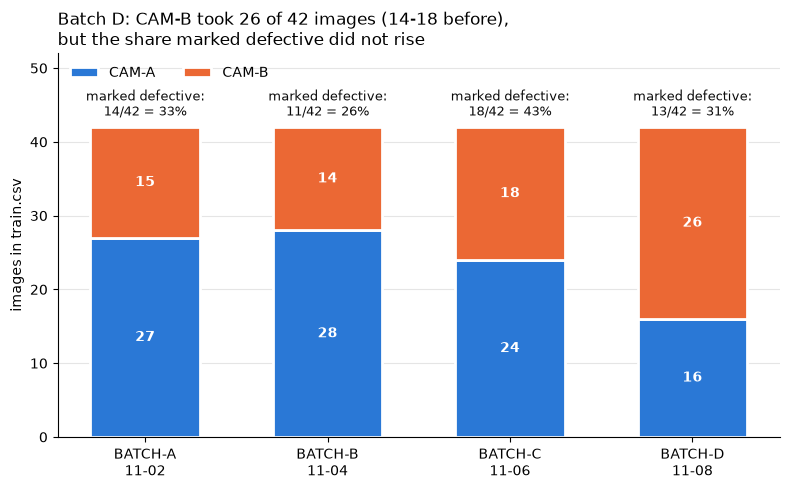

In [4]:
# A.3 — camera mix per batch and share marked defective (train.csv only)
from scipy.stats import fisher_exact, chi2_contingency   # scipy is installed as a dependency of scikit-learn

FIG_DIR = DATA_DIR / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

day = train["timestamp_utc"].str[:10]
batch_table = train.assign(day=day).groupby("batch").agg(
    date=("day", "min"),
    n_dates=("day", "nunique"),                                  # expected 1: one day per batch
    n_images=("image_id", "size"),
    n_cam_a=("camera", lambda c: (c == "CAM-A").sum()),
    n_cam_b=("camera", lambda c: (c == "CAM-B").sum()),
    n_defective=("inspector_label", "sum"),
).sort_index()
batch_table["cam_b_%"] = (100 * batch_table["n_cam_b"] / batch_table["n_images"]).round(1)
batch_table["defect_rate_%"] = (100 * batch_table["n_defective"] / batch_table["n_images"]).round(1)
print("images with a camera other than CAM-A / CAM-B:",
      (batch_table["n_images"] - batch_table["n_cam_a"] - batch_table["n_cam_b"]).sum())
display(batch_table)

# Is the CAM-B share in the last batch (D) different from batches A-C by chance? Fisher exact test, two-sided.
# Batch D was picked after looking at the table, so this p-value is optimistic; the chi-square tests below use all 4 batches.
is_d, is_b = train["batch"] == "BATCH-D", train["camera"] == "CAM-B"
table_2x2 = [[(is_d & is_b).sum(), (is_d & ~is_b).sum()], [(~is_d & is_b).sum(), (~is_d & ~is_b).sum()]]
p_value = fisher_exact(table_2x2)[1]
print(f"CAM-B share: batch D {table_2x2[0][0]}/{is_d.sum()} vs batches A-C {table_2x2[1][0]}/{(~is_d).sum()}, "
      f"Fisher exact p = {p_value:.4f} (n = {len(train)})")
for col in ["camera", "inspector_label"]:
    chi2, p, dof, expected = chi2_contingency(pd.crosstab(train["batch"], train[col]))
    print(f"chi-square, batch x {col} (all 4 batches): p = {p:.3f}, dof = {dof}, "
          f"smallest expected count = {expected.min():.1f} (n = {len(train)})")

# Stacked bars: CAM-A below, CAM-B above; count inside each segment, share marked defective above each bar
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(batch_table))
colors = {"CAM-A": "#2a78d6", "CAM-B": "#eb6834"}
ax.bar(x, batch_table["n_cam_a"], width=0.6, color=colors["CAM-A"], edgecolor="white", linewidth=2, label="CAM-A")
ax.bar(x, batch_table["n_cam_b"], width=0.6, bottom=batch_table["n_cam_a"], color=colors["CAM-B"],
       edgecolor="white", linewidth=2, label="CAM-B")
for i, row in enumerate(batch_table.itertuples()):
    ax.text(i, row.n_cam_a / 2, str(row.n_cam_a), ha="center", va="center", color="white", fontweight="bold")
    ax.text(i, row.n_cam_a + row.n_cam_b / 2, str(row.n_cam_b), ha="center", va="center", color="white", fontweight="bold")
    ax.text(i, row.n_images + 1,
            f"marked defective:\n{row.n_defective}/{row.n_images} = {row.n_defective / row.n_images:.0%}",
            ha="center", va="bottom", color="#0b0b0b", fontsize=9)
ax.set_xticks(x, [f"{b}\n{d[5:]}" for b, d in zip(batch_table.index, batch_table["date"])])
ax.set_ylabel("images in train.csv")
ax.set_ylim(0, 52)
earlier = batch_table.drop(index="BATCH-D")["n_cam_b"]
last = batch_table.loc["BATCH-D"]
ax.set_title(f"Batch D: CAM-B took {last.n_cam_b} of {last.n_images} images ({earlier.min()}-{earlier.max()} before),\n"
             "but the share marked defective did not rise", loc="left", fontsize=12)
ax.legend(loc="upper left", frameon=False, ncol=2, bbox_to_anchor=(0, 1.0))
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(FIG_DIR / "a3_camera_mix_by_batch.png", dpi=150)
print("saved:", FIG_DIR / "a3_camera_mix_by_batch.png")

In [5]:
# A.3 data notes (options not charted): exposure per camera, and shift label against the timestamp hour
print("train: images per camera x exposure_setting")
display(pd.crosstab(train["camera"], train["exposure_setting"], margins=True))

hour = pd.to_datetime(train["timestamp_utc"]).dt.hour
shift_by_hour = pd.crosstab(hour, train["shift"])
both = ((shift_by_hour["DAY"] > 0) & (shift_by_hour["NIGHT"] > 0)).sum()
print(f"train: hours (UTC) with images: {len(shift_by_hour)}, hours with both DAY and NIGHT images: {both}")

train: images per camera x exposure_setting


exposure_setting,AUTO,LOW,NORMAL,All
camera,,,,
CAM-A,65,0,30,95
CAM-B,15,48,10,73
All,80,48,40,168


train: hours (UTC) with images: 15, hours with both DAY and NIGHT images: 15


<div dir="rtl">

**תוצאות א.3**

**ממצא:** באצווה האחרונה (D, ‏08.11) צילמה CAM-B ‏26 מתוך 42 התמונות (62%), לעומת 14–18 מתוך 42 (33%–43%) באצוות A–C.
שיעור התמונות שסומנו כפגומות לא עלה באותה אצווה: 13 מתוך 42 (31%), לעומת 26%–43% באצוות הקודמות.

- **הרכב המצלמות:** לפי מבחן Fisher, הפער בין אצווה D לאצוות A–C אינו סביר כתוצאה של מקרה בלבד (p = 0.007). אצווה D נבחרה אחרי הסתכלות בנתונים, ולכן ערך זה אופטימי; מבחן חי-בריבוע על כל ארבע האצוות, בלי לבחור אצווה, נותן p = 0.035.
- **שיעור הפגומים:** מבחן חי-בריבוע על התיוג מול האצווה נותן p = 0.43, כלומר אין עדות להבדל בשיעור הפגומים בין האצוות.
- כל המבחנים חושבו על 168 תמונות `train.csv`.

**תובנה (השערה):** באצווה האחרונה השתנה הרכב המצלמות, אך שיעור הפגומים לפי הבודק לא השתנה.
אם העלייה בהתראות התרחשה באצווה האחרונה, ייתכן שהיא קשורה לתנאי הצילום ולא לאיכות הרכיבים.
זו השערה בלבד: בנתונים אין עמודת התראות, ואת ההבדל בתנאי הצילום בין CAM-B ל-CAM-A נמדוד בחלק ב.

**הערות נתונים:**
- חשיפה `LOW` מופיעה רק ב-CAM-B ‏(48 מתוך 73 תמונות CAM-B), ואילו ב-CAM-A אין אף תמונה כזו. לכן ההשוואה בין המצלמות בסעיף א.2 משלבת גם הבדל בחשיפה, ואי אפשר להפריד בין השניים.
- עמודת `shift` אינה תואמת את שעת הצילום: בכל 15 השעות שבהן יש תמונות (07:00–21:00 UTC) מופיעות גם תמונות DAY וגם תמונות NIGHT. לכן לא נשתמש בה כמדד לשעת הצילום.

</div>

<div dir="rtl">

## חלק ב — הבנת התמונות והפקת נתונים
### חלוקה לקבוצת פיתוח וקבוצת אימות
את החלוקה מבצעים כבר עכשיו, כדי שבחירת התמונות לדוגמה והמאפיינים תיעשה על קבוצת הפיתוח, וקבוצת האימות תשמש רק להערכה בחלק ד. חריג אחד: הרעיון של שלוש מדידות הלוח בחלק ג וההגדרות שלהן הגיעו מחקירה מוקדמת שראתה גם את תיוגי קבוצת האימות (פירוט בחלק ה).
החלוקה מרובדת לפי התיוג (נשמר יחס 2:1), עם 25% לאימות וזרע קבוע (`random_state=42`). אותה חלוקה תשמש בחלק ג ללא שינוי.

</div>

In [6]:
# Development / validation split of train.csv — fixed here and reused unchanged in Part C
from sklearn.model_selection import train_test_split

dev, val = train_test_split(train, test_size=0.25, stratify=train["inspector_label"], random_state=42)
split_counts = pd.crosstab(
    pd.Series(np.where(train.index.isin(dev.index), "dev", "val"), index=train.index, name="part"),
    train["inspector_label"], margins=True,
)
display(split_counts)
print("images in both parts:", len(set(dev["image_id"]) & set(val["image_id"])))

inspector_label,0,1,All
part,,,
dev,84,42,126
val,28,14,42
All,112,56,168


images in both parts: 0


<div dir="rtl">

### ב.1 שש תמונות לדוגמה
**למה דווקא שש התמונות האלה:** המטרה היא להראות את שני מקורות השונות בתמונות: סוג הפגם ותנאי הצילום.
לכן נבחרה תמונה פגומה אחת מכל אחד מארבעת סוגי הפגמים, ושתי תמונות תקינות, אחת מכל מצלמה, כדי לראות גם שונות שאינה פגם.
כל תמונה נבחרה באקראי מבין התמונות מהסוג שלה בקבוצת הפיתוח, עם זרע קבוע (`random_state=0`) שלא שונה אחרי שראינו את התוצאה.
העמודה `inspector_type` משמשת כאן רק לבחירת הדוגמאות ולכותרות. היא לא קיימת ב-`test.csv` ולא תשמש כקלט לכלל.

</div>

status: {'ok': 6}


,image_id,camera,exposure_setting,inspector_label,inspector_type,status,mean_gray_0_255
143,IMG_0207,CAM-A,NORMAL,0,none,ok,126.1
136,IMG_0196,CAM-B,LOW,0,none,ok,104.2
68,IMG_0098,CAM-B,LOW,1,stain,ok,121.5
160,IMG_0229,CAM-B,NORMAL,1,scratch,ok,81.4
49,IMG_0071,CAM-B,LOW,1,edge_chip,ok,168.4
50,IMG_0072,CAM-A,AUTO,1,missing_hole,ok,107.5


saved: results/figures/b1_sample_images.png


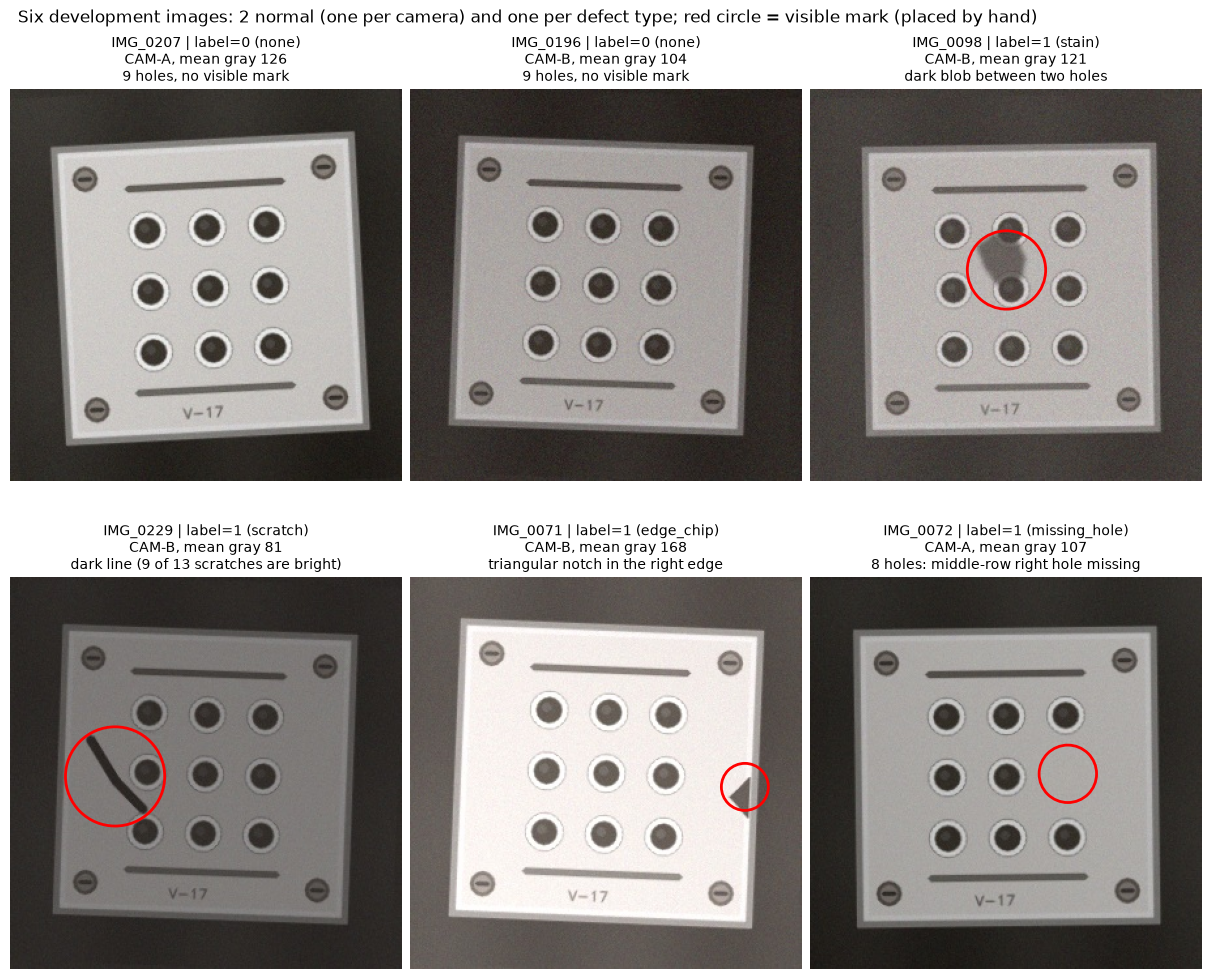

In [7]:
# B.1 — 6 sample images from the development part: 2 normal (one per camera) and 1 per defect type
import cv2

SAMPLE_PICKS = [("none", "CAM-A"), ("none", "CAM-B"), ("stain", None),
                ("scratch", None), ("edge_chip", None), ("missing_hole", None)]
picked = []
for defect_type, camera in SAMPLE_PICKS:
    pool = dev[dev["inspector_type"] == defect_type]
    if camera is not None:
        pool = pool[pool["camera"] == camera]
    picked.append(pool.sample(n=1, random_state=0).iloc[0])   # fixed seed, not changed after seeing the picks
samples = pd.DataFrame(picked)[["image_id", "file", "camera", "exposure_setting", "inspector_label", "inspector_type"]]

# What is visible in each picked image (from viewing it at full size) and where the mark is.
# Circles are placed by hand for illustration only: not detected, not a model input.
# (x, y, radius) in pixels of the 300x300 image; drawn only if that exact image was picked.
VISIBLE = {
    "IMG_0207": ("9 holes, no visible mark", None),
    "IMG_0196": ("9 holes, no visible mark", None),
    "IMG_0098": ("dark blob between two holes", (150, 138, 30)),
    "IMG_0229": ("dark line (9 of 13 scratches are bright)", (80, 152, 38)),
    "IMG_0071": ("triangular notch in the right edge", (256, 160, 18)),
    "IMG_0072": ("8 holes: middle-row right hole missing", (197, 150, 22)),
}

fig, axes = plt.subplots(2, 3, figsize=(12, 10), layout="constrained")   # constrained: titles never overlap images
status, mean_gray = [], []
for ax, row in zip(axes.flat, samples.itertuples()):
    img = cv2.imread(str(DATA_DIR / row.file))
    ax.axis("off")
    if img is None:                      # a missing or broken file is recorded, not skipped
        status.append("unreadable"); mean_gray.append(np.nan)
        ax.set_title(f"{row.image_id}: could not be read", fontsize=10)
        continue
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float64)
    status.append("ok"); mean_gray.append(round(gray.mean(), 1))
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))   # OpenCV loads BGR, matplotlib expects RGB
    caption, circle = VISIBLE.get(row.image_id, ("not described", None))
    if circle is not None:
        x, y, r = circle
        ax.add_patch(plt.Circle((x, y), r, fill=False, edgecolor="red", linewidth=2))
    ax.set_title(f"{row.image_id} | label={row.inspector_label} ({row.inspector_type})\n"
                 f"{row.camera}, mean gray {gray.mean():.0f}\n{caption}", fontsize=10)
samples["status"], samples["mean_gray_0_255"] = status, mean_gray   # mean gray: 0 = black, 255 = white
fig.suptitle("Six development images: 2 normal (one per camera) and one per defect type; red circle = visible mark (placed by hand)", x=0.01, ha="left")
fig.savefig(FIG_DIR / "b1_sample_images.png", dpi=120)
print("status:", samples["status"].value_counts().to_dict())
display(samples.drop(columns="file"))
print("saved:", FIG_DIR / "b1_sample_images.png")

<div dir="rtl">

**תוצאות ב.1: ההבדל החזותי העיקרי הוא שבתמונות הפגומות יש סימן קטן ומקומי על הלוח, ואילו ההבדלים בין התמונות התקינות הם כלליים, על כל התמונה (בהירות, תנאי צילום).** כל 6 התמונות נקראו בהצלחה (ממוצע אפור: 0 = שחור, 255 = לבן).

- **הדוגמה הברורה ביותר** היא החור החסר (IMG_0072: ‏8 חורים במקום 9), כי אפשר לספור אותו, אבל הוא רק 9 מתוך 56 הפגמים. השאר הם כתם, קו או שקע בשפת הלוח. השריטה שבדוגמה כהה, אבל ב-9 מתוך 13 השריטות ב-`train.csv` הקו בהיר.
- **הבהירות משתנה גם בלי פגם:** שתי התמונות התקינות שונות בבהירות (126 לעומת 104), ובשש הדוגמאות היא נעה בין 81 ל-168. זה הבדל בין התמונות האלה ולא בין המצלמות (בסעיף ב.3, בקבוצת הפיתוח: חציון 115.0 ב-CAM-A ו-111.1 ב-CAM-B).
- **למה זה חשוב:** מאפיין שמחושב על כל התמונה צפוי לתפוס את תנאי הצילום ולא את הפגם (נבדק בסעיף ב.3). כדי לתפוס את הפגם צריך מאפיין שמסתכל על הלוח, למשל השטח הכהה עליו או מספר החורים.
- **הערה על התיוגים (תצפית חזותית):** מתוך 15 תמונות ה-stain בקבוצת הפיתוח, ב-6 נראה כתם כהה, ב-IMG_0163 נראה קו בהיר, וב-8 לא נראה כתם גם בהגדלה פי 2 (IMG_0004, 0006, 0007, 0011, 0034, 0073, 0100, 0213). כבדיקה של איכות התיוגים הסתכלנו גם ב-5 תמונות ה-stain של קבוצת האימות: בסך הכול 11 מתוך 20 בלי כתם נראה. ייתכן שהתיוג שגוי או שהכתם חלש מכדי להיראות; זה הסימן הראשון לכך שתיוגי הבודק אינם מושלמים.

</div>

<div dir="rtl">

### ב.2 פונקציה להפקת שני מאפיינים
הפונקציה `image_features` קוראת תמונה ומחזירה שני מאפיינים, מחושבים על כל התמונה:
- **בהירות** (`brightness`): ממוצע רמת האפור, בין 0 (שחור) ל-255 (לבן). ערך גבוה = תמונה בהירה יותר.
- **חדות** (`sharpness`): השונות של מסנן Laplacian על תמונת האפור. ערך גבוה = יותר פרטים דקים, ערך נמוך = תמונה מטושטשת.

**למה דווקא שני אלה:**
- **מה הם נותנים:** בהירות מודדת את התאורה והחשיפה, וחדות מודדת את המיקוד (תופסת תמונות מטושטשות, בעיית איכות שאינה פגם).
- **על מה הבחירה מבוססת:** אלה שתי הדוגמאות הפשוטות שהמשימה עצמה מציעה; הן בודקות את התחזית מסעיף ב.1 שמאפיין על כל התמונה עוקב אחרי תנאי הצילום; והן מתחברות לממצא מסעיף א.3 שתנאי הצילום השתנו באצווה האחרונה.
- **ההשפעה הצפויה:** צפוי שיפרידו רק מעט בין תקין לפגום. את זה נבדוק בסעיף ב.3, ובחלק ג אכן הוספנו שלוש מדידות של הלוח עצמו.

**מאפיינים אחרים שנשקלו ולא נבחרו:**

| מאפיין שנשקל | למה לא נבחר |
|---|---|
| ניגודיות, מספר קצוות | גם הם מאפיינים של כל התמונה, עם אותה חולשה צפויה, ובלי קשר לממצאים הקודמים |
| ספירת חורים | מתאימה יותר לפגמים, אבל דורשת גלאי מכוונן ומכסה רק 9 מתוך 56 פגמים; נשמרת כאפשרות לחלק ג |
| שטח הכתמים הכהים על הלוח | מכוון לכתמים ולחורים חסרים, אבל דורש זיהוי של הלוח וכוונון, ולכן אינו "מאפיין פשוט". השתמשנו בו בחלק ג, אחרי שסעיף ב.3 הראה שמאפיינים פשוטים אינם מספיקים |

**בדיקות עם תשובה ידועה:** לפני שמשתמשים בפונקציה, בודקים אותה על תמונה אחת ועל גרסאות שלה, שאת התוצאה עליהן אפשר לצפות מראש: אותה תמונה פעמיים, תמונה שהוחשכה לחצי, תמונה מטושטשת, תמונה אפורה אחידה וקובץ שאינו קיים.

</div>

In [8]:
# B.2 — two simple image features, computed on the whole image (as in the brief's examples)
def features_from_bgr(img_bgr):
    """Two features of one BGR image (as loaded by cv2.imread).
    brightness: mean gray level, 0 = black to 255 = white; higher = brighter image.
    sharpness:  variance of the Laplacian of the gray image; higher = more fine detail, lower = blurrier.
    """
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY).astype(np.float64)   # float64 before any arithmetic
    return {"brightness": gray.mean(), "sharpness": cv2.Laplacian(gray, cv2.CV_64F).var()}


def image_features(path):
    """Read one image file and return brightness, sharpness and a status.
    A missing or broken file gives status "unreadable" and NaN values; the run does not stop.
    """
    img = cv2.imread(str(path))
    if img is None:
        return {"brightness": np.nan, "sharpness": np.nan, "status": "unreadable"}
    return {**features_from_bgr(img), "status": "ok"}


# Known-answer tests on one development image (IMG_0207, normal, from B.1)
test_path = DATA_DIR / "images" / "IMG_0207.jpg"
img = cv2.imread(str(test_path))
assert img is not None, f"test image could not be read: {test_path}"
base = features_from_bgr(img)
darker = features_from_bgr(np.round(img.astype(np.float64) * 0.5).astype(np.uint8))   # every pixel halved
blurred = features_from_bgr(cv2.GaussianBlur(img, (0, 0), sigmaX=2))
flat = features_from_bgr(np.full_like(img, 128))                                       # plain gray image
again = image_features(test_path)
missing = image_features(DATA_DIR / "images" / "does_not_exist.jpg")

tests = pd.DataFrame([
    ("same image read twice", "identical values",
     f"{again['brightness']:.2f} / {again['sharpness']:.1f}",
     again["brightness"] == base["brightness"] and again["sharpness"] == base["sharpness"]),
    ("darkened to half: brightness", f"about {base['brightness'] / 2:.1f} (half of {base['brightness']:.1f})",
     f"{darker['brightness']:.1f}", abs(darker["brightness"] - base["brightness"] / 2) < 1),
    ("darkened to half: sharpness", "about 0.25 x original (0.20-0.30)",
     f"{darker['sharpness'] / base['sharpness']:.3f} x", 0.20 <= darker["sharpness"] / base["sharpness"] <= 0.30),
    ("blurred (sigma 2): brightness", "almost unchanged (within 1)",
     f"{blurred['brightness']:.1f} vs {base['brightness']:.1f}", abs(blurred["brightness"] - base["brightness"]) < 1),
    ("blurred (sigma 2): sharpness", "below 0.5 x original",
     f"{blurred['sharpness'] / base['sharpness']:.3f} x", blurred["sharpness"] / base["sharpness"] < 0.5),
    ("plain gray image (128)", "brightness 128, sharpness 0",
     f"{flat['brightness']:.1f} / {flat['sharpness']:.1f}", flat["brightness"] == 128 and flat["sharpness"] == 0),
    ("missing file", "status unreadable, values NaN",
     f"{missing['status']} / {missing['brightness']}", missing["status"] == "unreadable" and np.isnan(missing["brightness"])),
], columns=["test", "expected", "got", "passed"])
print(f"IMG_0207: brightness = {base['brightness']:.2f} (0-255), sharpness = {base['sharpness']:.1f}")
display(tests)
assert tests["passed"].all(), "a known-answer test failed; see the table above"
print(f"known-answer tests passed: {tests['passed'].sum()} of {len(tests)}")

IMG_0207: brightness = 126.11 (0-255), sharpness = 498.9


[ WARN:0@0.776] global loadsave.cpp:278 findDecoder imread_('images/does_not_exist.jpg'): can't open/read file: check file path/integrity


,test,expected,got,passed
0,same image read twice,identical values,126.11 / 498.9,True
1,darkened to half: brightness,about 63.1 (half of 126.1),63.0,True
2,darkened to half: sharpness,about 0.25 x original (0.20-0.30),0.255 x,True
3,blurred (sigma 2): brightness,almost unchanged (within 1),126.1 vs 126.1,True
4,blurred (sigma 2): sharpness,below 0.5 x original,0.017 x,True
5,plain gray image (128),"brightness 128, sharpness 0",128.0 / 0.0,True
6,missing file,"status unreadable, values NaN",unreadable / nan,True


known-answer tests passed: 7 of 7


<div dir="rtl">

**תוצאות ב.2:** כל 7 הבדיקות עברו, על התמונה IMG_0207 (בהירות 126.1, חדות 498.9).
- **אותה תמונה פעמיים:** ערכים זהים, כלומר הפונקציה יציבה.
- **הוחשכה לחצי:** הבהירות ירדה ל-63.0 (חצי מ-126.1), והחדות ירדה ל-0.255 מהמקור, כצפוי (כשמחלקים כל פיקסל ב-2, השונות קטנה פי 4).
- **טשטוש:** הבהירות לא השתנתה (126.1), והחדות ירדה ל-0.017 מהמקור. כלומר החדות מגיבה לטשטוש והבהירות לא.
- **תמונה אפורה אחידה:** בהירות 128 וחדות 0, בדיוק כצפוי.
- **קובץ שאינו קיים:** הפונקציה מחזירה סטטוס `unreadable` וערכים ריקים, בלי לעצור את הריצה (הודעת ה-WARN של OpenCV מעל הטבלה צפויה בבדיקה הזו).

</div>

<div dir="rtl">

### ב.3 השוואת הבהירות בין תמונות תקינות לפגומות
- מחשבים את שני המאפיינים לכל 168 התמונות ב-`train.csv`, ושומרים טבלה עם שורה לכל תמונה (`results/features_train.csv`) לפני כל סיכום.
- ההשוואה עצמה נעשית על קבוצת הפיתוח בלבד (126 תמונות), כדי שקבוצת האימות לא תשפיע על הבחירות (מה בכל זאת השפיע מפורט בחלק ה).
- **המאפיין שמושווה הוא בהירות,** כי היא בודקת ישירות את התחזית מסעיף ב.1. ההשוואה מפוצלת לפי מצלמה, כי בחלק א ראינו שהרכב המצלמות משתנה.
- **מדד ההפרדה הוא AUC:** הסיכוי שתמונה פגומה אקראית בהירה יותר מתמונה תקינה אקראית. ‏0.5 = אין הפרדה; ככל שהערך רחוק יותר מ-0.5 (למעלה או למטה), ההפרדה טובה יותר.

</div>

saved results/features_train.csv: 168 rows, one per image


status,ok,All
part,,
dev,126,126
val,42,42
All,168,168


development images used: 126, excluded as unreadable: 0


n  brightness_median  brightness_q1  brightness_q3  \
camera inspector_label                                                        
CAM-A  0                47              115.0          107.8          118.6   
       1                22              109.7          107.2          118.0   
CAM-B  0                37              111.1          102.7          123.8   
       1                20              118.5          102.9          122.2   

                        brightness_std  sharpness_median  
camera inspector_label                                    
CAM-A  0                           6.2             400.8  
       1                           7.3             410.5  
CAM-B  0                          16.5             609.3  
       1                          17.7             540.9

brightness AUC on dev: {'CAM-A': 0.44, 'CAM-B': 0.52, 'all': 0.49} | n: {'CAM-A': 69, 'CAM-B': 57, 'all': 126}
saved: results/figures/b3_brightness_by_label_camera.png


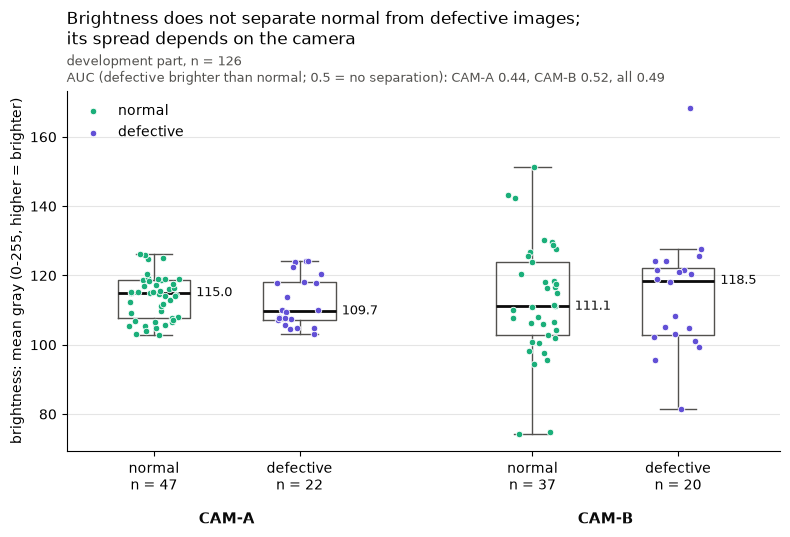

In [9]:
# B.3 — features for every image in train.csv (one row per image, saved first); comparison on the development part
from sklearn.metrics import roc_auc_score

part = np.where(train["image_id"].isin(dev["image_id"]), "dev", "val")
feats = pd.DataFrame([image_features(DATA_DIR / f) for f in train["file"]], index=train.index)
features_train = pd.concat(
    [train[["image_id", "camera", "exposure_setting", "batch", "inspector_label"]].assign(part=part), feats], axis=1
)
features_train.to_csv(DATA_DIR / "results" / "features_train.csv", index=False)
print("saved results/features_train.csv:", len(features_train), "rows, one per image")
display(pd.crosstab(features_train["part"], features_train["status"], margins=True))

# Comparison: development part only (validation stays unseen until Part D); unreadable images excluded and counted
in_dev = features_train["part"] == "dev"
d = features_train[in_dev & (features_train["status"] == "ok")]
print(f"development images used: {len(d)}, excluded as unreadable: {(in_dev & (features_train['status'] != 'ok')).sum()}")

summary = d.groupby(["camera", "inspector_label"]).agg(
    n=("image_id", "size"),
    brightness_median=("brightness", "median"),
    brightness_q1=("brightness", lambda s: s.quantile(0.25)),
    brightness_q3=("brightness", lambda s: s.quantile(0.75)),
    brightness_std=("brightness", "std"),
    sharpness_median=("sharpness", "median"),
).round(1)
display(summary)   # brightness: mean gray 0-255, higher = brighter; sharpness: Laplacian variance, higher = sharper

# AUC = chance that a random defective image is brighter than a random normal one; 0.5 = no separation
auc = {name: roc_auc_score(g["inspector_label"], g["brightness"])
       for name, g in [("CAM-A", d[d["camera"] == "CAM-A"]), ("CAM-B", d[d["camera"] == "CAM-B"]), ("all", d)]}
print("brightness AUC on dev:", {k: round(v, 2) for k, v in auc.items()},
      "| n:", {"CAM-A": int((d["camera"] == "CAM-A").sum()), "CAM-B": int((d["camera"] == "CAM-B").sum()), "all": len(d)})

# Box plot with every image shown as a dot: one pair (normal, defective) per camera, a gap between the cameras
groups = [(cam, lab) for cam in ["CAM-A", "CAM-B"] for lab in [0, 1]]
positions = [0, 1, 2.6, 3.6]                   # gap between the two camera pairs
values = [d[(d["camera"] == cam) & (d["inspector_label"] == lab)]["brightness"].to_numpy() for cam, lab in groups]
label_color = {0: "#1baf7a", 1: "#6250d6"}     # normal / defective (camera colours from A.3 are not reused)
label_name = {0: "normal", 1: "defective"}
fig, ax = plt.subplots(figsize=(8, 5.6))
ax.boxplot(values, positions=positions, widths=0.5, showfliers=False,
           boxprops=dict(color="#52514e"), whiskerprops=dict(color="#52514e"), capprops=dict(color="#52514e"),
           medianprops=dict(color="#0b0b0b", linewidth=2))
rng = np.random.default_rng(0)                 # fixed jitter so the figure is identical on every run
for pos, (cam, lab), vals in zip(positions, groups, values):
    ax.scatter(pos + rng.uniform(-0.17, 0.17, len(vals)), vals, s=22, color=label_color[lab],
               edgecolor="white", linewidth=0.6, zorder=3, label=label_name[lab] if cam == "CAM-A" else None)
    ax.text(pos + 0.29, np.median(vals), f"{np.median(vals):.1f}", va="center", ha="left",
            fontsize=9, color="#0b0b0b")    # median written next to its line
ax.set_xticks(positions, [f"{label_name[lab]}\nn = {len(v)}" for (cam, lab), v in zip(groups, values)])
for cam, center in [("CAM-A", 0.5), ("CAM-B", 3.1)]:   # camera name once under each pair
    ax.text(center, -0.17, cam, transform=ax.get_xaxis_transform(), ha="center", va="top",
            fontsize=11, fontweight="bold", color="#0b0b0b")
ax.set_xlim(-0.6, 4.3)
ax.set_ylabel("brightness: mean gray (0-255, higher = brighter)")
ax.set_title("Brightness does not separate normal from defective images;\nits spread depends on the camera",
             loc="left", fontsize=12, pad=34)
ax.text(0, 1.015, f"development part, n = {len(d)}\n"
        f"AUC (defective brighter than normal; 0.5 = no separation): "
        f"CAM-A {auc['CAM-A']:.2f}, CAM-B {auc['CAM-B']:.2f}, all {auc['all']:.2f}",
        transform=ax.transAxes, fontsize=9, color="#52514e", va="bottom")
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(FIG_DIR / "b3_brightness_by_label_camera.png", dpi=150)
print("saved:", FIG_DIR / "b3_brightness_by_label_camera.png")

<div dir="rtl">

**תוצאות ב.3:** כל 168 התמונות נקראו (0 לא קריאות), והטבלה נשמרה עם 168 שורות. ההשוואה נעשתה על 126 תמונות הפיתוח.

- **הבהירות כמעט לא מפרידה בין תקין לפגום:** ‏AUC = 0.44 ב-CAM-A ‏(69 תמונות), 0.52 ב-CAM-B ‏(57 תמונות) ו-0.49 בסך הכול (126 תמונות). כל הערכים קרובים ל-0.5, כלומר קרובים לניחוש.
- **הכיוון אפילו מתהפך בין המצלמות:** ב-CAM-A הפגומות כהות יותר (חציון 109.7 לעומת 115.0), וב-CAM-B הן בהירות יותר (118.5 לעומת 111.1). בשתי המצלמות הקבוצות חופפות כמעט לגמרי, ולכן זה נראה כמו רעש ולא כמו סימן לפגם.
- **הפיזור תלוי במצלמה ולא בתיוג:** סטיית התקן של הבהירות היא 6.2–7.3 ב-CAM-A לעומת 16.5–17.7 ב-CAM-B, בשתי קבוצות התיוג.
- **הבהירות של התמונות התקינות כמעט זהה בשתי המצלמות** (חציון 115.0 ב-CAM-A לעומת 111.1 ב-CAM-B), כפי שנאמר בסעיף ב.1. ההבדל בין המצלמות הוא בפיזור, לא בחציון.
- **גם החדות דומה בין התיוגים בתוך כל מצלמה** (חציון 401 לעומת 411 ב-CAM-A, ו-609 לעומת 541 ב-CAM-B).

**התוצאה תואמת את התחזית מסעיף ב.1:** הבהירות משקפת את תנאי הצילום ולא את הפגם: החציון כמעט זהה בין המצלמות, ורק הפיזור תלוי במצלמה.
**ההשלכה לחלק ג:** מודל שמבוסס רק על שני המאפיינים האלה צפוי להיות קרוב לניחוש. לכן בחלק ג הוספנו שלוש מדידות של הלוח עצמו.

</div>

<div dir="rtl">

## חלק ג — פתרון ראשוני
### ג.1 שלב א: שלוש מדידות של הלוח עצמו
בסעיף ב.3 ראינו שמאפיינים שמחושבים על כל התמונה עוקבים אחרי המצלמה ולא אחרי הפגם. לכן כאן מודדים את **הלוח עצמו**, וכל מדידה מכוונת לסוג פגם שראינו בסעיף ב.1:

| מדידה | מה היא מודדת | איזה פגם היא אמורה לתפוס |
|---|---|---|
| `dark_share` | איזה חלק משטח הלוח כהה (חורים, ברגים, פסים, וכל דבר נוסף) | כתם או שריטה כהה מוסיפים שטח כהה; חור חסר מוריד שטח כהה |
| `bright_line_len` | אורך, בפיקסלים, של הצורה הבהירה הדקה הארוכה ביותר (שפת חור היא כ-38 פיקסלים) | שריטה בהירה (9 מתוך 13 השריטות) |
| `dent_depth` | עומק, בפיקסלים, של השקע העמוק ביותר בקו המתאר של הלוח | שקע בשפת הלוח (edge_chip) |

- **עמידות לבהירות:** רמות האפור מנורמלות בכל תמונה בנפרד (0 = רקע, 1 = משטח הלוח), כך שהמדידות לא אמורות לעקוב אחרי הבהירות הכללית.
- **קובץ שלא נקרא או לוח שלא נמצא** מקבלים סטטוס (`unreadable`, `no_plate`) וערכים ריקים, והריצה לא נעצרת.
- **מקור ההגדרות:** הרעיון וההגדרות (הספים 0.75 ו-0.72 וגדלי החלונות) הגיעו מחקירה מוקדמת שראתה תיוגים מכל `train.csv`, כולל קבוצת האימות. כאן הכול נכתב ונבדק מחדש בקוד שלנו, וההשוואות ייעשו על קבוצת הפיתוח בלבד, אבל ייתכן שהתוצאה על קבוצת האימות בחלק ד תהיה מעט אופטימית.

**בדיקות עם תשובה ידועה:** משנים עותק של תמונה תקינה מקבוצת הפיתוח (IMG_0207) בדרך ידועה, ובודקים שכל מדידה מגיבה כצפוי: כתם, חור שמולא, קו בהיר, שקע בשפה, כל התמונה כהה יותר ב-30%, ותמונה מטושטשת.

</div>

In [10]:
# C.1 step A — three measurements of the plate itself, each aimed at one kind of defect
# All grey levels are rescaled per image (0 = background, 1 = plate surface), so the measurements do not follow
# overall brightness, which B.3 showed is driven by the camera rather than the defect.
PLATE_LEVEL = 0.75      # pixels above 75% of the way from background to plate surface count as plate
DARK_LEVEL = 0.72       # pixels below 72% of that way, inside the plate, count as dark (holes, screws, bars, stains)
EDGE_MARGIN_PX = 6      # measure dark share and bright lines at least 6 px inside the plate outline
TOPHAT_PX = 11          # bright shapes thinner than 11 px stand out in a top-hat filter (rims, scratches)
BRIGHT_LEVEL = 0.25     # a thin shape counts as bright if it is 25% of the background-to-plate span above its surroundings
MIN_SHAPE_PX = 15       # ignore bright specks smaller than 15 px (noise)


def plate_features_from_gray(gray8):
    """Three plate measurements from one 8-bit grey image. Returns NaN values and status "no_plate" if no plate is found.
    dark_share:      share of the plate area that is dark (0-1). A stain adds dark area; a missing hole removes it.
    bright_line_len: length in px of the longest thin bright shape (diagonal of its bounding box). A hole rim is about
                     38 px; a bright scratch is longer.
    dent_depth:      depth in px of the deepest dent in the plate outline relative to its convex hull. A chipped edge
                     makes a dent.
    """
    smooth = cv2.GaussianBlur(gray8, (5, 5), 0).astype(np.float64)
    background, surface = np.percentile(smooth, [10, 80])          # typical background and plate-surface grey levels
    span = max(surface - background, 1.0)
    level = (smooth - background) / span                             # 0 = background, 1 = plate surface

    plate = cv2.morphologyEx((level > PLATE_LEVEL).astype(np.uint8), cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
    contours, _ = cv2.findContours(plate, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return {"dark_share": np.nan, "bright_line_len": np.nan, "dent_depth": np.nan, "status": "no_plate"}
    outline = max(contours, key=cv2.contourArea)

    # dent_depth: OpenCV returns defect depths in 1/256 px
    hull_idx = cv2.convexHull(outline, returnPoints=False)
    dents = cv2.convexityDefects(outline, hull_idx)
    # no dents: OpenCV returns None or an empty array, depending on the version
    dent_depth = 0.0 if dents is None or dents.size == 0 else dents.reshape(-1, 4)[:, 3].max() / 256.0

    # region to measure in: the filled convex hull, shrunk so the edge itself is not counted
    region = np.zeros_like(gray8)
    cv2.fillConvexPoly(region, cv2.convexHull(outline), 255)
    k = 2 * EDGE_MARGIN_PX + 1
    region = cv2.erode(region, np.ones((k, k), np.uint8)) > 0

    dark = ((level < DARK_LEVEL) & region).astype(np.uint8)
    dark = cv2.morphologyEx(dark, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))   # remove single-pixel noise
    dark_share = dark.sum() / region.sum()

    tophat = cv2.morphologyEx(gray8, cv2.MORPH_TOPHAT,
                              cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (TOPHAT_PX, TOPHAT_PX))).astype(np.float64)
    thin = ((tophat > BRIGHT_LEVEL * span) & region).astype(np.uint8)
    n, _, stats, _ = cv2.connectedComponentsWithStats(thin)
    lengths = [np.hypot(stats[i, cv2.CC_STAT_WIDTH], stats[i, cv2.CC_STAT_HEIGHT])
               for i in range(1, n) if stats[i, cv2.CC_STAT_AREA] >= MIN_SHAPE_PX]
    bright_line_len = max(lengths, default=0.0)

    return {"dark_share": float(dark_share), "bright_line_len": float(bright_line_len),
            "dent_depth": float(dent_depth), "status": "ok"}


def plate_features(path):
    """Read one image file; a missing or broken file gives status "unreadable" and NaN values, without stopping."""
    img = cv2.imread(str(path))
    if img is None:
        return {"dark_share": np.nan, "bright_line_len": np.nan, "dent_depth": np.nan, "status": "unreadable"}
    return plate_features_from_gray(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY))

In [11]:
# C.1 step A (continued) — known-answer tests for plate_features
# ---- Known-answer tests: edit a copy of one normal development image (IMG_0207) in a known way ----
# Positions were read off this image and checked in a picture: a clean plate point, one hole, the middle of the right edge.
gray = cv2.cvtColor(cv2.imread(str(DATA_DIR / "images" / "IMG_0207.jpg")), cv2.COLOR_BGR2GRAY)
base = plate_features_from_gray(gray)
BACKGROUND_GREY, PLATE_GREY = 38, 201              # 10th and 80th percentile grey of this image
CLEAN_X, CLEAN_Y = 232, 125                        # clean plate surface, about 30 px from any hole or the edge
HOLE_X, HOLE_Y = 196, 103                          # centre of the top-right hole
NOTCH = np.array([[268, 160], [267, 132], [249, 147]], np.int32)   # 15 px deep triangle at the middle of the right edge

edits = {
    "blob": cv2.circle(gray.copy(), (CLEAN_X, CLEAN_Y), 10, 103, -1),                       # dark stain, r = 10 px
    "filled": cv2.circle(gray.copy(), (HOLE_X, HOLE_Y), 16, PLATE_GREY, -1),                  # hole and rim painted over
    "line": cv2.line(gray.copy(), (CLEAN_X, CLEAN_Y - 30), (CLEAN_X, CLEAN_Y + 30), 255, 3),  # bright scratch, 60 px
    "chipped": cv2.fillPoly(gray.copy(), [NOTCH], BACKGROUND_GREY),                           # chipped edge
    "darker": np.round(gray.astype(np.float64) * 0.7).astype(np.uint8),                       # whole image at 70%
    "blurred": cv2.GaussianBlur(gray, (0, 0), sigmaX=2),                                      # out of focus
    "flat": np.full_like(gray, 128),                                                          # no plate at all
}
f = {name: plate_features_from_gray(im) for name, im in edits.items()}
again = plate_features(DATA_DIR / "images" / "IMG_0207.jpg")
missing = plate_features(DATA_DIR / "images" / "does_not_exist.jpg")

tests = pd.DataFrame([
    ("same image read twice", "identical values",
     f"{again['dark_share']:.4f} / {again['bright_line_len']:.1f} / {again['dent_depth']:.1f}",
     all(again[k] == base[k] for k in ("dark_share", "bright_line_len", "dent_depth"))),
    ("dark blob painted (stain)", "dark_share goes up",
     f"{base['dark_share']:.4f} -> {f['blob']['dark_share']:.4f}", f["blob"]["dark_share"] > base["dark_share"]),
    ("one hole painted over (missing hole)", "dark_share goes down",
     f"{base['dark_share']:.4f} -> {f['filled']['dark_share']:.4f}", f["filled"]["dark_share"] < base["dark_share"]),
    ("bright line 60 px drawn (scratch)", "bright_line_len 55-70 px (longer = merged with something)",
     f"{base['bright_line_len']:.1f} -> {f['line']['bright_line_len']:.1f}", 55 <= f["line"]["bright_line_len"] <= 70),
    ("triangle cut into edge (chip)", "dent_depth >= 8 px",
     f"{base['dent_depth']:.1f} -> {f['chipped']['dent_depth']:.1f}", f["chipped"]["dent_depth"] >= 8),
    ("whole image darkened to 70%", "almost unchanged: 0.002 / 5 px / 1 px (a defect moves dark_share ~0.007)",
     f"{f['darker']['dark_share']:.4f} / {f['darker']['bright_line_len']:.1f} / {f['darker']['dent_depth']:.1f}",
     abs(f["darker"]["dark_share"] - base["dark_share"]) < 0.002
     and abs(f["darker"]["bright_line_len"] - base["bright_line_len"]) < 5
     and abs(f["darker"]["dent_depth"] - base["dent_depth"]) < 1),
    ("blurred (sigma 2) - known limitation", "bright_line_len falls below 20 px (hole rims vanish)",
     f"{base['bright_line_len']:.1f} -> {f['blurred']['bright_line_len']:.1f}; dark_share {f['blurred']['dark_share']:.4f}",
     f["blurred"]["bright_line_len"] < 20),
    ("plain gray image", "status no_plate", f["flat"]["status"], f["flat"]["status"] == "no_plate"),
    ("missing file", "status unreadable, values NaN",
     f"{missing['status']} / {missing['dark_share']}", missing["status"] == "unreadable" and np.isnan(missing["dark_share"])),
], columns=["test", "expected", "got", "passed"])
print(f"IMG_0207: dark_share = {base['dark_share']:.4f}, bright_line_len = {base['bright_line_len']:.1f} px, "
      f"dent_depth = {base['dent_depth']:.1f} px")
display(tests)
assert tests["passed"].all(), "a known-answer test failed; see the table above"
print(f"known-answer tests passed: {tests['passed'].sum()} of {len(tests)}")

IMG_0207: dark_share = 0.1265, bright_line_len = 39.6 px, dent_depth = 1.1 px


[ WARN:0@1.193] global loadsave.cpp:278 findDecoder imread_('images/does_not_exist.jpg'): can't open/read file: check file path/integrity


,test,expected,got,passed
0,same image read twice,identical values,0.1265 / 39.6 / 1.1,True
1,dark blob painted (stain),dark_share goes up,0.1265 -> 0.1336,True
2,one hole painted over (missing hole),dark_share goes down,0.1265 -> 0.1191,True
3,bright line 60 px drawn (scratch),bright_line_len 55-70 px (longer = merged with...,39.6 -> 65.2,True
4,triangle cut into edge (chip),dent_depth >= 8 px,1.1 -> 15.4,True
5,whole image darkened to 70%,almost unchanged: 0.002 / 5 px / 1 px (a defec...,0.1272 / 39.6 / 1.0,True
6,blurred (sigma 2) - known limitation,bright_line_len falls below 20 px (hole rims v...,39.6 -> 0.0; dark_share 0.1280,True
7,plain gray image,status no_plate,no_plate,True
8,missing file,"status unreadable, values NaN",unreadable / nan,True


known-answer tests passed: 9 of 9


<div dir="rtl">

**תוצאות המדידות:** כל 9 הבדיקות עברו. על התמונה המקורית: ‏`dark_share` = 0.1265, ‏`bright_line_len` = 39.6 פיקסלים (שפת חור, כצפוי), ‏`dent_depth` = 1.1 פיקסלים.

| בדיקה | מה ציפינו | מה קיבלנו |
|---|---|---|
| כתם כהה (רדיוס 10) | `dark_share` עולה | 0.1265 ← 0.1336 |
| חור אחד נצבע בצבע הלוח | `dark_share` יורד | 0.1265 ← 0.1191 |
| קו בהיר של 60 פיקסלים | `bright_line_len` בין 55 ל-70 | 39.6 ← 65.2 |
| שקע של 15 פיקסלים באמצע השפה | `dent_depth` לפחות 8 | 1.1 ← 15.4 |
| כל התמונה ב-70% בהירות | כמעט ללא שינוי (עד 0.002 ב-`dark_share`, פחות מהשפעת פגם, כ-0.007) | ‏0.1272 / 39.6 / 1.0 |
| טשטוש (מגבלה ידועה) | `bright_line_len` יורד מתחת ל-20 | 39.6 ← 0.0 |
| תמונה אפורה אחידה / קובץ שאינו קיים | `no_plate` / `unreadable` | כצפוי |

- **עמידות לבהירות:** בניגוד למאפיין הבהירות בסעיף ב.3, שלוש המדידות כמעט לא משתנות כשהתמונה כהה יותר (‏`dark_share` זז ב-0.0008 בלבד), כלומר הן לא אמורות לרשת את ההבדל בין המצלמות.
- **טשטוש הוא מגבלה:** בתמונה מטושטשת שפות החורים נעלמות, ולכן `bright_line_len` יורד ל-0 ושריטה בהירה עלולה להיעלם. 7 מתוך 9 התמונות המטושטשות מאוד נמצאות ב-`test.csv`, ולכן התחזיות עליהן פחות אמינות.
- **מה הבדיקות לא מוכיחות:** הן מראות שכל מדידה מגיבה נכון לשינוי ידוע, אבל לא שהמדידות מפרידות בין תמונות פגומות לתקינות. את זה נבדוק בכלל עצמו, על קבוצת הפיתוח.
- **שקיפות:** בזמן הפיתוח, שתי עריכות בבדיקות הונחו תחילה במקום שגוי (השקע נחתך בפינת הלוח, והקו נגע בשפת חור), והבדיקות נכשלו. תיקנו את מיקום העריכות; הפונקציה עצמה לא שונתה.
- הודעת ה-WARN של OpenCV מעל הטבלה צפויה בבדיקת הקובץ החסר.

</div>

<div dir="rtl">

### ג.1 שלב ב: כלל החלטה — תמונה חשודה אם אחת ממדידות הלוח חורגת מהטווח של לוח תקין
- **הכלל:** לכל אחת משלוש המדידות נקבע סף, האחוזון ה-95 של התמונות התקינות בקבוצת הפיתוח. תמונה מסומנת כחשודה כפגומה אם **לפחות מדידה אחת** מעל הסף שלה.
- **`dark_share` נמדד כמרחק מהערך של לוח תקין טיפוסי** (`dark_dev`; הערך הטיפוסי הוא החציון של התמונות התקינות), כי הוא זז לשני הכיוונים: כתם מעלה אותו וחור חסר מוריד אותו.
- **למה כלל ולא מודל:** כל מדידה מכוונת לסוג פגם אחר, ולכן "אחת מהן חורגת" מתאר את הפגמים כפי שהם נראים. כל סימון מגיע עם סיבה (איזו מדידה חרגה), ואין מה לכוונן: האחוזון נקבע מראש ולא נבחר לפי התוצאה.
- **הציון:** כל מדידה ממוקמת על סקאלה של לוח תקין: (ערך − ערך טיפוסי של לוח תקין) / (סף − ערך טיפוסי), וערכים שליליים נקבעים ל-0. כך 0 = לוח תקין טיפוסי ו-1 = בדיוק על הסף. ‏r = הגבוה מבין שלוש המדידות, ו-`score` = ‏r / (1 + r), בין 0 ל-1: ‏0.5 = בדיוק על הסף, וערך גבוה יותר = חשוד יותר. ‏`predicted_defect` = 1 כאשר `score` > 0.5. הציון מדרג תמונות, ואינו הסתברות מכוילת.
- **איך בודקים:** 5-fold cross-validation על קבוצת הפיתוח בלבד. כל תמונה מקבלת ציון מכלל שנלמד בלי לראות אותה. משווים לשתי שיטות אחרות: מודל הבסיס על מאפייני סעיף ב (בהירות וחדות), ורגרסיה לוגיסטית על אותן שלוש מדידות. בקבוצת האימות לא נוגעים עד חלק ד.

</div>

In [12]:
# C.1 — decision rule on the plate measurements, compared with two alternatives (5-fold CV, development part only)
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import precision_score, recall_score

RULE_COLS = ["dark_dev", "bright_line_len", "dent_depth"]
NORMAL_PCT = 0.95        # cut-off = 95th percentile of normal plates; fixed in advance, not searched

# 1) Plate measurements for every image in train.csv, one row per image, saved before any summary
plate = pd.DataFrame([plate_features(DATA_DIR / f) for f in train["file"]], index=train.index)
features_all = features_train.rename(columns={"status": "photo_status"}).join(plate.rename(columns={"status": "plate_status"}))
features_all.to_csv(DATA_DIR / "results" / "features_train_all.csv", index=False)
print("saved results/features_train_all.csv:", len(features_all), "rows, one per image")
display(pd.crosstab(features_all["part"], features_all["plate_status"], margins=True))


# 2) The rule
def add_dark_dev(rows, ref):
    """dark_dev = distance of dark_share from a typical normal plate (a stain raises it, a missing hole lowers it)."""
    return rows.assign(dark_dev=(rows["dark_share"] - ref).abs())


def fit_rule(rows):
    """Learn the rule from labelled rows: the typical normal dark_share, the typical value of each measurement on a
    normal plate (median), and one cut-off per measurement (95th percentile of normal plates)."""
    normal = add_dark_dev(rows[rows["inspector_label"] == 0], rows.loc[rows["inspector_label"] == 0, "dark_share"].median())
    ref = normal["dark_share"].median()
    typical, cuts = normal[RULE_COLS].median(), normal[RULE_COLS].quantile(NORMAL_PCT)
    assert (cuts > typical).all(), "each cut-off must lie above the typical normal value"
    return ref, cuts, typical


def apply_rule(rows, ref, cuts, typical):
    """Flag an image if any measurement is above its cut-off.
    Each measurement is placed on a normal-plate scale: (value - typical) / (cut-off - typical), negatives set to 0,
    so 0 = a typical normal plate and 1 = exactly at the cut-off. r = the largest of the three.
    score = r / (1 + r): 0 = typical normal plate, 0.5 = exactly at a cut-off, higher = more suspicious.
    It ranks images; it is not a calibrated probability. reason = which measurements are above their cut-off.
    """
    excess = ((add_dark_dev(rows, ref)[RULE_COLS] - typical) / (cuts - typical)).clip(lower=0)
    worst = excess.max(axis=1)
    reason = excess.gt(1).apply(lambda r: ", ".join(r.index[r]), axis=1)
    return pd.DataFrame({"score": worst / (1 + worst), "predicted_defect": (worst > 1).astype(int), "reason": reason},
                        index=rows.index)


# 3) 5-fold cross-validation on the development part: every image is scored by a rule/model that did not see it
d = features_all.loc[dev.index]                                       # same order as the split in Part B
bad = d["plate_status"] != "ok"
print(f"development images: {len(d)}, excluded (plate_status not ok): {bad.sum()}")
d = d[~bad].assign(log_sharpness=lambda x: np.log(x["sharpness"]))
y = d["inspector_label"]
oof = pd.DataFrame(index=d.index)
for train_idx, test_idx in StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(d, y):
    fit_rows, score_rows = d.iloc[train_idx], d.iloc[test_idx]
    ref, cuts, typical = fit_rule(fit_rows)                           # learned on the training folds only
    out = apply_rule(score_rows, ref, cuts, typical)
    oof.loc[out.index, ["rule_score", "rule_pred", "rule_reason"]] = out[["score", "predicted_defect", "reason"]].to_numpy()
    for name, cols, a, b in [("baseline", ["brightness", "log_sharpness"], fit_rows, score_rows),
                             ("logistic", RULE_COLS, add_dark_dev(fit_rows, ref), add_dark_dev(score_rows, ref))]:
        model = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced"))
        p = model.fit(a[cols], a["inspector_label"]).predict_proba(b[cols])[:, 1]
        oof.loc[b.index, f"{name}_score"], oof.loc[b.index, f"{name}_pred"] = p, (p >= 0.5).astype(int)

candidates = {"baseline: brightness + sharpness, logistic regression": "baseline",
              "plate measurements, logistic regression": "logistic",
              "rule: any plate measurement above the normal 95th percentile": "rule"}
comparison = pd.DataFrame({
    label: {"AUC": roc_auc_score(y, oof[f"{k}_score"].astype(float)),
            "precision": precision_score(y, oof[f"{k}_pred"].astype(int), zero_division=0),
            "recall": recall_score(y, oof[f"{k}_pred"].astype(int)),
            "flagged": int(oof[f"{k}_pred"].astype(int).sum())}
    for label, k in candidates.items()}).T
print(f"\n5-fold CV on the development part (n = {len(d)}, {int(y.sum())} marked defective); "
      "AUC 0.5 = chance, precision = share of flags that are marked defective, recall = share of marked defects flagged")
display(comparison.round(2))

saved results/features_train_all.csv: 168 rows, one per image


plate_status,ok,All
part,,
dev,126,126
val,42,42
All,168,168


development images: 126, excluded (plate_status not ok): 0

5-fold CV on the development part (n = 126, 42 marked defective); AUC 0.5 = chance, precision = share of flags that are marked defective, recall = share of marked defects flagged


,AUC,precision,recall,flagged
"baseline: brightness + sharpness, logistic regression",0.50,0.32,0.43,56.0
"plate measurements, logistic regression",0.82,0.86,0.76,37.0
rule: any plate measurement above the normal 95th percentile,0.85,0.85,0.81,40.0


In [13]:
# C.1 (continued) — where the rule is right and wrong, and the final rule
# 4) Where the rule is right and wrong (out-of-fold, development part)
d = d.join(oof[["rule_pred", "rule_reason"]]).join(train[["inspector_type"]])   # type: only to read the result
d["rule_pred"] = d["rule_pred"].astype(int)
print("rule, marked-defective images caught by inspector_type (used here only to read the result):")
display(d[d["inspector_label"] == 1].groupby("inspector_type")["rule_pred"].agg(n="size", caught="sum"))
STAINS_NO_VISIBLE_MARK = ["IMG_0004", "IMG_0006", "IMG_0007", "IMG_0011", "IMG_0034", "IMG_0073", "IMG_0100", "IMG_0213"]  # B.1
stain = d[d["inspector_type"] == "stain"]
no_mark = stain["image_id"].isin(STAINS_NO_VISIBLE_MARK)
print(f"stains with a visible mark: caught {stain.loc[~no_mark, 'rule_pred'].sum()} of {(~no_mark).sum()}; "
      f"stains with no visible mark (B.1): caught {stain.loc[no_mark, 'rule_pred'].sum()} of {no_mark.sum()}")
false_alarms = d[(d["inspector_label"] == 0) & (d["rule_pred"] == 1)]
print(f"normal-labelled images flagged: {len(false_alarms)} of {int((y == 0).sum())}")
display(false_alarms[["image_id", "camera", "rule_reason"]])

# 5) The final rule: learned once on all development images; used in C.3 for the test predictions
RULE_REF, RULE_CUTS, RULE_TYPICAL = fit_rule(d)
print(f"final rule (all {len(d)} development images): typical normal dark_share = {RULE_REF:.4f}")
print("  typical normal value:", {k: round(v, 4) for k, v in RULE_TYPICAL.items()})
print("  cut-off (95th pct):  ", {k: round(v, 4) for k, v in RULE_CUTS.items()})
rule_scores = oof["rule_score"].astype(float)
print(f"out-of-fold rule scores within 0.45-0.55 (close to the cut-off): {rule_scores.between(0.45, 0.55).sum()} of {len(d)}")

rule, marked-defective images caught by inspector_type (used here only to read the result):


,n,caught
inspector_type,,
edge_chip,11,11
missing_hole,6,6
scratch,10,10
stain,15,7


stains with a visible mark: caught 6 of 7; stains with no visible mark (B.1): caught 1 of 8
normal-labelled images flagged: 6 of 84


,image_id,camera,rule_reason
29,IMG_0040,CAM-B,dent_depth
63,IMG_0092,CAM-A,dent_depth
79,IMG_0112,CAM-B,"dark_dev, dent_depth"
149,IMG_0214,CAM-B,"dark_dev, dent_depth"
92,IMG_0133,CAM-B,dark_dev
116,IMG_0167,CAM-A,dark_dev


final rule (all 126 development images): typical normal dark_share = 0.1263
  typical normal value: {'dark_dev': 0.0005, 'bright_line_len': 38.1838, 'dent_depth': 1.0547}
  cut-off (95th pct):   {'dark_dev': 0.0039, 'bright_line_len': 39.598, 'dent_depth': 1.242}
out-of-fold rule scores within 0.45-0.55 (close to the cut-off): 16 of 126


<div dir="rtl">

**תוצאות ג.1:** שלוש המדידות חושבו לכל 168 התמונות (0 כשלים) ונשמרו בטבלה עם שורה לכל תמונה (`results/features_train_all.csv`). ההשוואה נעשתה על 126 תמונות הפיתוח (42 מסומנות כפגומות).

| שיטה | AUC | Precision | Recall | סומנו |
|---|---|---|---|---|
| בסיס: בהירות + חדות, רגרסיה לוגיסטית | 0.50 | 0.32 | 0.43 | 56 |
| מדידות הלוח, רגרסיה לוגיסטית | 0.82 | 0.86 | 0.76 | 37 |
| **כלל: מדידה כלשהי מעל האחוזון ה-95 של התמונות התקינות** | **0.85** | **0.85** | **0.81** | 40 |

- **מאפייני סעיף ב מפרידים כמו ניחוש** (AUC 0.50), כפי שסעיף ב.3 צפה. מדידות הלוח מעלות את ה-AUC ל-0.82–0.85.
- **הכלל והרגרסיה כמעט שווים;** ההבדל קטן מהרעש הצפוי עם 126 תמונות. בחרנו בכלל כי כל סימון שלו מוסבר ואין בו כוונון.
- **לפי סוג פגם** (ב-cross-validation, כל תמונה קיבלה ציון מכלל שלא ראה אותה): שקע בשפה 11 מתוך 11, חור חסר 6 מתוך 6, שריטה 10 מתוך 10, כתם 7 מתוך 15.
- **רוב ההחטאות בכתמים הן תמונות בלי כתם נראה:** מתוך 7 הכתמים בקבוצת הפיתוח שרואים בהם סימן (סעיף ב.1) הכלל תפס 6, ומתוך 8 הכתמים שלא רואים בהם סימן הוא תפס רק 1 (IMG_0007).
- **ב-4 מתוך 6 "התראות השווא" נראה פגם בבדיקה חזותית:** שקע בשפה ב-IMG_0092, וחור חסר ב-IMG_0112, ‏IMG_0133 ו-IMG_0167. ב-IMG_0040 וב-IMG_0214 ‏(CAM-B) נראית רק השתקפות אור. במדדים כל 6 נספרות כהתראות שווא, לפי התיוגים.
- **הספים צמודים:** ‏`bright_line_len` ‏39.6 פיקסלים (בערך אורך שפת חור), ‏`dent_depth` ‏1.24 פיקסלים (ערך טיפוסי 1.05) ו-`dark_dev` ‏0.0039. ההשלכה נבדקת בסעיף ד.1.
- **סף שני:** בחלק ד נציג גם את האחוזון ה-99 ואת המחיר שלו.
- **על הציון:** בגרסה הקודמת (יחס מדידה/סף) ‏87 מתוך 126 ציונים נדחסו בין 0.45 ל-0.55; בסקאלה הנוכחית 16, וה-AUC עלה מ-0.84 ל-0.85, בלי שאף החלטה 0/1 השתנתה. את הבעיה הבחנו לראשונה בציוני המבחן, וההחלטה התבססה על קבוצת הפיתוח.
- **הסתייגות:** השווינו שלוש שיטות על אותה חלוקה של ה-cross-validation, ולכן הבחירה מעט אופטימית. הכלל הסופי נלמד פעם אחת על כל 126 תמונות הפיתוח, וישמש בסעיף ג.3 לתחזיות על `test.csv`.

</div>

<div dir="rtl">

### ג.2 חלוקה לקבוצת פיתוח וקבוצת אימות
החלוקה נעשתה בתחילת חלק ב (התא "חלוקה לקבוצת פיתוח וקבוצת אימות"): חלוקה מרובדת לפי התיוג, 25% לאימות, `random_state=42` ‏(126 תמונות פיתוח, 42 תמונות אימות). אותה חלוקה משמשת כאן ללא שינוי: הכלל נבנה על קבוצת הפיתוח, וההערכה על קבוצת האימות נעשית בחלק ד. החריג (החקירה המוקדמת שראתה את תיוגי האימות) מתואר בתחילת חלק ב ובחלק ה.

</div>

<div dir="rtl">

### ג.3 תחזיות ל-`test.csv` ‏(הקובץ `predictions.csv`)
- **הכלל:** הכלל הסופי מסעיף ג.1, כפי שנלמד על 126 תמונות הפיתוח, בלי שום שינוי. כך חלק ד יעריך על קבוצת האימות בדיוק את הכלל שהפיק את התחזיות.
- **מה לא עושים:** ‏`test.csv` לא משמש ללמידה, לכוונון או להערכה של הכלל (הערה על סקאלת הציון בחלק ה); אין תיוג ידני של תמונות מבחן ואין תחזית לפי מזהה תמונה. כל תחזית נובעת מהמדידות ומהכלל בלבד.
- **תמונה שלא ניתן למדוד עוצרת את הריצה,** כי המשימה דורשת תחזית לכל 72 התמונות, ומילוי ערך ברירת מחדל היה מסתיר שגיאה.
- **לפני השמירה** בודקים את הקובץ מול דרישות המשימה: 72 שורות, אותם מזהים כמו ב-`test.csv`, העמודות `image_id,predicted_defect,score`, ערכים 0/1 וציון בין 0 ל-1.
- **קובץ פירוט נוסף** (`results/test_predictions_detail.csv`, לא חלק מההגשה) שומר לכל תמונה את המדידות, את סיבת הסימון ואת סימון הטשטוש.

</div>

In [14]:
# C.3 — predictions for test.csv with the final rule from C.1 (learned on the development part only; test is not used
# to fit, tune or evaluate anything)
BLUR_SHARPNESS = 50      # reporting only: in train.csv the 2 blurred images measure 8.2 and 11.5, the next is 107.9

# 1) Measure every test image; any image that cannot be measured stops the run (the brief needs all 72 predictions)
test_plate = pd.DataFrame([plate_features(DATA_DIR / f) for f in test["file"]], index=test.index)
test_photo = pd.DataFrame([image_features(DATA_DIR / f) for f in test["file"]], index=test.index)
print("test images:", len(test), "| plate status:", test_plate["status"].value_counts().to_dict(),
      "| photo status:", test_photo["status"].value_counts().to_dict())
not_ok = test.loc[(test_plate["status"] != "ok") | (test_photo["status"] != "ok"), "image_id"].tolist()
assert not not_ok, f"these test images could not be measured, decide what to do with them: {not_ok}"

# 2) Apply the rule
out = apply_rule(test_plate, RULE_REF, RULE_CUTS, RULE_TYPICAL)
predictions = pd.DataFrame({"image_id": test["image_id"],
                            "predicted_defect": out["predicted_defect"].astype(int),
                            "score": out["score"]})

# 3) Check the file against the brief before saving it
sample_columns = list(pd.read_csv(DATA_DIR / "sample_predictions.csv", nrows=0).columns)
checks = pd.DataFrame([
    ("72 rows", len(predictions) == 72),
    ("every image_id once", predictions["image_id"].is_unique),
    ("same image_ids as test.csv", set(predictions["image_id"]) == set(test["image_id"])),
    ("columns image_id,predicted_defect,score (as sample_predictions.csv)",
     list(predictions.columns) == ["image_id", "predicted_defect", "score"] == sample_columns),
    ("predicted_defect only 0 or 1", predictions["predicted_defect"].isin([0, 1]).all()),
    ("score between 0 and 1, no empty values", predictions["score"].between(0, 1).all()),
    ("predicted_defect = 1 exactly when score > 0.5",
     (predictions["predicted_defect"] == (predictions["score"] > 0.5).astype(int)).all()),
], columns=["check", "passed"])
display(checks)
assert checks["passed"].all(), "predictions.csv does not meet the brief; see the table above"
predictions.to_csv(DATA_DIR / "predictions.csv", index=False)
print(f"saved predictions.csv: {len(predictions)} rows; flagged as suspected defective: "
      f"{predictions['predicted_defect'].sum()} ({predictions['predicted_defect'].mean():.0%})")
print(f"scores within 0.45-0.55 (close to the cut-off): {predictions['score'].between(0.45, 0.55).sum()} of {len(predictions)}; "
      f"score quartiles: {predictions['score'].quantile([0, .25, .5, .75, 1]).round(3).tolist()}")

# 4) Detail file (not a deliverable): measurements, reason for each flag, and a blur marker for Part E
detail = pd.concat([test[["image_id", "camera", "exposure_setting", "batch"]],
                    add_dark_dev(test_plate, RULE_REF)[["dark_share", "dark_dev", "bright_line_len", "dent_depth"]],
                    test_photo[["brightness", "sharpness"]], out], axis=1)
detail["blurred"] = detail["sharpness"] < BLUR_SHARPNESS
detail.to_csv(DATA_DIR / "results" / "test_predictions_detail.csv", index=False)
print("saved results/test_predictions_detail.csv:", len(detail), "rows")

# 5) Summaries by group, with counts
for col in ["camera", "batch"]:
    display(detail.groupby(col).agg(n=("image_id", "size"), flagged=("predicted_defect", "sum"),
                                    flagged_share=("predicted_defect", "mean")).round(2))
print("flags by reason:", detail.loc[detail["predicted_defect"] == 1, "reason"].value_counts().to_dict())
print(f"blurred test images (sharpness < {BLUR_SHARPNESS}): {int(detail['blurred'].sum())}")
display(detail.loc[detail["blurred"], ["image_id", "camera", "batch", "sharpness", "score", "predicted_defect", "reason"]]
        .round(3))

test images: 72 | plate status: {'ok': 72} | photo status: {'ok': 72}


,check,passed
0,72 rows,True
1,every image_id once,True
2,same image_ids as test.csv,True
3,"columns image_id,predicted_defect,score (as sa...",True
4,predicted_defect only 0 or 1,True
5,"score between 0 and 1, no empty values",True
6,predicted_defect = 1 exactly when score > 0.5,True


saved predictions.csv: 72 rows; flagged as suspected defective: 26 (36%)
scores within 0.45-0.55 (close to the cut-off): 5 of 72; score quartiles: [0.0, 0.16, 0.335, 0.68, 0.992]
saved results/test_predictions_detail.csv: 72 rows


,n,flagged,flagged_share
camera,,,
CAM-A,45,16,0.36
CAM-B,27,10,0.37


,n,flagged,flagged_share
batch,,,
BATCH-A,18,4,0.22
BATCH-B,18,4,0.22
BATCH-C,18,11,0.61
BATCH-D,18,7,0.39


flags by reason: {'dark_dev': 9, 'dark_dev, dent_depth': 6, 'dent_depth': 5, 'bright_line_len': 4, 'dark_dev, bright_line_len': 2}
blurred test images (sharpness < 50): 7


,image_id,camera,batch,sharpness,score,predicted_defect,reason
31,IMG_0109,CAM-B,BATCH-B,8.926,0.385,0,
33,IMG_0115,CAM-B,BATCH-B,13.746,0.000,0,
54,IMG_0184,CAM-B,BATCH-D,7.192,0.338,0,
58,IMG_0194,CAM-B,BATCH-D,5.172,0.792,1,dark_dev
59,IMG_0197,CAM-B,BATCH-D,10.919,0.180,0,
64,IMG_0216,CAM-B,BATCH-D,5.905,0.167,0,
67,IMG_0227,CAM-B,BATCH-D,10.226,0.328,0,


<div dir="rtl">

**תוצאות ג.3:** כל 72 תמונות המבחן נמדדו (0 כשלים), כל 7 הבדיקות של הקובץ עברו, ו-`predictions.csv` נשמר עם 72 שורות.

- **26 מתוך 72 תמונות (36%) סומנו כחשודות.** זו בדיקת שפיות בלבד: השיעור דומה ל-32% בקבוצת הפיתוח, אבל זו לא ראיה שהכלל צודק, כי אין לנו תיוגים ל-`test.csv`.
- **לפי מצלמה השיעור כמעט זהה:** ‏16 מתוך 45 ב-CAM-A ‏(36%) ו-10 מתוך 27 ב-CAM-B ‏(37%). זה נכון לתמונות המבחן בלבד: על 168 התמונות המתויגות הכלל מסמן 40% מתמונות CAM-B לעומת 27% מ-CAM-A, בעוד שהבודק סימן 36% ו-32% (חלק ה). כלומר, הכלל נוטה לסמן יותר את CAM-B.
- **לפי אצווה** (18 תמונות בכל אחת): ‏A ‏4, ‏B ‏4, ‏C ‏11, ‏D ‏7. גם ב-`train.csv` אצווה C היא זו עם שיעור התיוגים כפגומים הגבוה ביותר (42.9%). זה דיווח בלבד; לא שינינו דבר בעקבותיו.
- **סיבות הסימון:** ‏`dark_dev` לבד 9, ‏`dark_dev` עם `dent_depth` ‏6, ‏`dent_depth` לבד 5, ‏`bright_line_len` לבד 4, ‏`dark_dev` עם `bright_line_len` ‏2.
- **פיזור הציונים:** הציונים נעים בין 0 ל-0.99 (חציון 0.34), ורק 5 מתוך 72 נמצאים בין 0.45 ל-0.55. הציון הגבוה ביותר שלא סומן הוא 0.50 (מדידה שבדיוק על הסף), והנמוך ביותר שסומן הוא 0.60.
- **3 סימונים נשענים על הפרש של פיקסל או שניים:** IMG_0149 ו-IMG_0237 בגלל `dent_depth` של 1.46 ו-1.34 (הסף 1.24), ו-IMG_0134 בגלל קו של 40.3 פיקסלים (הסף 39.6). לא שינינו את הספים, כי שינוי אחרי שראינו את סימוני המבחן היה כוונון לפי `test.csv` (פירוט בסעיף ד.1).
- **7 תמונות מבחן מטושטשות מאוד** (חדות מתחת ל-50; ב-`train.csv` החדות של שתי התמונות המטושטשות היא 8.2 ו-11.5, והבאה אחריהן 107.9), כולן מ-CAM-B, 5 מהן באצווה D. אחת סומנה (IMG_0194, ציון 0.79), והשאר קיבלו ציונים 0–0.39. אלה התחזיות הפחות אמינות: בבדיקות של המדידות ראינו שטשטוש מעלים שריטות בהירות.

</div>

<div dir="rtl">

## חלק ד — בדיקת התוצאות
### ד.1 Confusion Matrix, ‏Precision ו-Recall על קבוצת האימות
- מעריכים **פעם אחת**, על 42 תמונות האימות בלבד, את הכלל שהפיק את `predictions.csv` (האחוזון ה-95). אחרי ההערכה לא משנים דבר בכלל.
- **המטריצה מוצגת כטבלה וכאיור,** לשני הספים זה לצד זה.
- **סף שני להשוואה:** האחוזון ה-99, שגם הוא נלמד על קבוצת הפיתוח בלבד.
- **ליד כל תוצאה:** שיעור הבסיס (כמה תמונות מסומנות כפגומות, כלומר ה-Precision של בחירה אקראית), ותוצאת ה-cross-validation על קבוצת הפיתוח, כדי לראות כמה משקל אפשר לתת לחלוקה אחת של 42 תמונות.

</div>

validation images: 42, excluded (plate_status not ok): 0
precision = flagged images that are marked defective / all flagged; recall = marked-defective images flagged / all marked defective; picking at random would give precision = the base rate


,cut-off,data,n,marked defective (base rate),flagged,TP,FP,FN,TN,precision,recall
0,95th pct (delivered),validation (once),42,14 (33%),15,11,4,3,24,0.73,0.79
1,99th pct,validation (once),42,14 (33%),8,8,0,6,28,1.00,0.57
2,95th pct (delivered),"development, 5-fold CV",126,42 (33%),40,34,6,8,78,0.85,0.81
3,99th pct,"development, 5-fold CV",126,42 (33%),30,28,2,14,82,0.93,0.67


confusion matrix, delivered rule (95th percentile), validation part:


,predicted 0,predicted 1
marked normal (0),24,4
marked defective (1),3,11


saved: results/figures/d1_confusion_matrix.png


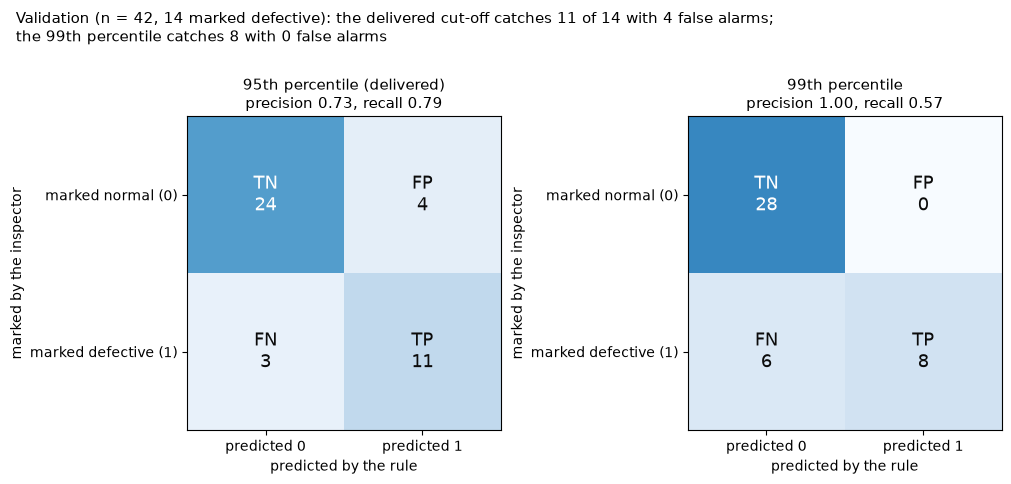

,n,marked defective (base rate),TP,FP,FN,precision,recall
camera,,,,,,,
CAM-A,26,8 (31%),7,1,1,0.88,0.88
CAM-B,16,6 (38%),4,3,2,0.57,0.67


highest values among normal-labelled development images (these set the 99th-percentile cut-offs):
  dark_dev: 95th cut 0.00395, 99th cut 0.008335; top normal-labelled: [('IMG_0112', 0.0109), ('IMG_0214', 0.0078)]
  bright_line_len: 95th cut 39.6, 99th cut 39.6; top normal-labelled: [('IMG_0145', 39.598), ('IMG_0065', 39.598)]
  dent_depth: 95th cut 1.242, 99th cut 4.681; top normal-labelled: [('IMG_0092', 15.9375), ('IMG_0214', 2.375)]
validation errors (delivered rule): 7


,image_id,error,inspector_type,camera,score,reason,dark_dev,bright_line_len,dent_depth
18,IMG_0025,missed,stain,CAM-B,0.2039,,0.0014,38.1838,1.0742
43,IMG_0062,false alarm,none,CAM-A,0.5558,dent_depth,0.0015,38.1838,1.2891
108,IMG_0158,false alarm,none,CAM-B,0.6715,dent_depth,0.0006,38.8973,1.4375
147,IMG_0212,false alarm,none,CAM-B,0.5431,dent_depth,0.0025,39.5980,1.2773
150,IMG_0215,false alarm,none,CAM-B,0.7435,dent_depth,0.0021,38.1838,1.5977
28,IMG_0039,missed,stain,CAM-A,0.1866,,0.0003,38.1838,1.0977
78,IMG_0111,missed,stain,CAM-B,0.3353,,0.0002,38.8973,1.0859


In [15]:
# D.1 — evaluation on the validation part, once. Nothing in the rule is changed after this cell.
from sklearn.metrics import confusion_matrix

v = features_all.loc[val.index].join(train[["inspector_type", "file"]])
bad = v["plate_status"] != "ok"
print(f"validation images: {len(v)}, excluded (plate_status not ok): {bad.sum()}")
v = v[~bad]
yv = v["inspector_label"]

# Second cut-off for comparison: the 99th percentile of normal development images (learned on development only)
dev_normal = add_dark_dev(d[d["inspector_label"] == 0], RULE_REF)
RULE_CUTS_99 = dev_normal[RULE_COLS].quantile(0.99)

# The same 99th-percentile rule, cross-validated on development (same folds as C.1), for the comparison row
oof99 = pd.Series(0, index=d.index)
for train_idx, test_idx in StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(d, d["inspector_label"]):
    fit_rows = d.iloc[train_idx]
    ref, _, typical = fit_rule(fit_rows)
    cuts99 = add_dark_dev(fit_rows[fit_rows["inspector_label"] == 0], ref)[RULE_COLS].quantile(0.99)
    oof99.iloc[test_idx] = apply_rule(d.iloc[test_idx], ref, cuts99, typical)["predicted_defect"].to_numpy()


def counts(y_true, y_pred, data, cut):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {"cut-off": cut, "data": data, "n": len(y_true), "marked defective (base rate)":
            f"{int(y_true.sum())} ({y_true.mean():.0%})", "flagged": int(tp + fp), "TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "precision": round(tp / (tp + fp), 2) if tp + fp else np.nan, "recall": round(tp / (tp + fn), 2)}


val_95 = apply_rule(v, RULE_REF, RULE_CUTS, RULE_TYPICAL)
val_99 = apply_rule(v, RULE_REF, RULE_CUTS_99, RULE_TYPICAL)
summary_d = pd.DataFrame([
    counts(yv, val_95["predicted_defect"], "validation (once)", "95th pct (delivered)"),
    counts(yv, val_99["predicted_defect"], "validation (once)", "99th pct"),
    counts(d["inspector_label"], d["rule_pred"], "development, 5-fold CV", "95th pct (delivered)"),
    counts(d["inspector_label"], oof99, "development, 5-fold CV", "99th pct"),
])
print("precision = flagged images that are marked defective / all flagged; recall = marked-defective images flagged / "
      "all marked defective; picking at random would give precision = the base rate")
display(summary_d)

# Confusion matrix of the delivered rule on validation
cm = pd.DataFrame(confusion_matrix(yv, val_95["predicted_defect"], labels=[0, 1]),
                  index=["marked normal (0)", "marked defective (1)"], columns=["predicted 0", "predicted 1"])
print("confusion matrix, delivered rule (95th percentile), validation part:")
display(cm)

# The same as a figure: delivered cut-off and 99th-percentile cut-off side by side, each cell named
CELL_NAMES = np.array([["TN", "FP"], ["FN", "TP"]])
mats = {"95th percentile (delivered)": confusion_matrix(yv, val_95["predicted_defect"], labels=[0, 1]),
        "99th percentile": confusion_matrix(yv, val_99["predicted_defect"], labels=[0, 1])}
fig, axes = plt.subplots(1, 2, figsize=(10, 4.9), layout="constrained")
for ax, (name, m) in zip(axes, mats.items()):
    ax.imshow(m, cmap="Blues", vmin=0, vmax=len(yv))
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{CELL_NAMES[i, j]}\n{m[i, j]}", ha="center", va="center", fontsize=13,
                    color="white" if m[i, j] > len(yv) / 2 else "#0b0b0b")
    ax.set_xticks([0, 1], ["predicted 0", "predicted 1"])
    ax.set_yticks([0, 1], ["marked normal (0)", "marked defective (1)"])
    ax.set_xlabel("predicted by the rule")
    ax.set_ylabel("marked by the inspector")
    tp, fp, fn = m[1, 1], m[0, 1], m[1, 0]
    ax.set_title(f"{name}\nprecision {tp / (tp + fp):.2f}, recall {tp / (tp + fn):.2f}", fontsize=11)
m95, m99 = mats.values()
fig.suptitle(f"Validation (n = {len(yv)}, {int(yv.sum())} marked defective): the delivered cut-off catches "
             f"{m95[1, 1]} of {int(yv.sum())} with {m95[0, 1]} false alarms;\nthe 99th percentile catches "
             f"{m99[1, 1]} with {m99[0, 1]} false alarms", x=0.01, ha="left", fontsize=11)
fig.savefig(FIG_DIR / "d1_confusion_matrix.png", dpi=150)
print("saved:", FIG_DIR / "d1_confusion_matrix.png")
display(fig)          # show it here, next to its table, instead of at the end of the cell
plt.close(fig)

# The same result by camera, with counts
v_eval = v.join(val_95)
by_cam = v_eval.groupby("camera").apply(lambda g: pd.Series(counts(g["inspector_label"], g["predicted_defect"], "", "")))
display(by_cam[["n", "marked defective (base rate)", "TP", "FP", "FN", "precision", "recall"]])

# Why the 99th percentile loses defects: which normal-labelled development images set those cut-offs
print("highest values among normal-labelled development images (these set the 99th-percentile cut-offs):")
for col in RULE_COLS:
    top = dev_normal.nlargest(2, col)
    print(f"  {col}: 95th cut {RULE_CUTS[col]:.4g}, 99th cut {RULE_CUTS_99[col]:.4g}; top normal-labelled:",
          [(r.image_id, round(getattr(r, col), 4)) for r in top.itertuples()])

# Every validation error, for D.2 (looked at after the evaluation; nothing is changed because of it)
errors = add_dark_dev(v_eval[v_eval["inspector_label"] != v_eval["predicted_defect"]], RULE_REF).assign(
    error=lambda e: np.where(e["predicted_defect"] == 1, "false alarm", "missed"))
print(f"validation errors (delivered rule): {len(errors)}")
display(errors[["image_id", "error", "inspector_type", "camera", "score", "reason", "dark_dev", "bright_line_len",
                "dent_depth"]].round(4))

<div dir="rtl">

**תוצאות ד.1** (קבוצת האימות: 42 תמונות, 14 מסומנות כפגומות = 33%):

| סף | נתונים | סומנו | TP | FP | FN | TN | Precision | Recall |
|---|---|---|---|---|---|---|---|---|
| **אחוזון 95 (הכלל שהוגש)** | **אימות** | 15 | 11 | 4 | 3 | 24 | **0.73** | **0.79** |
| אחוזון 99 | אימות | 8 | 8 | 0 | 6 | 28 | 1.00 | 0.57 |
| אחוזון 95 | פיתוח, 5-fold CV ‏(126) | 40 | 34 | 6 | 8 | 78 | 0.85 | 0.81 |
| אחוזון 99 | פיתוח, 5-fold CV ‏(126) | 30 | 28 | 2 | 14 | 82 | 0.93 | 0.67 |

- **Precision של 0.73 לעומת שיעור בסיס של 33%:** מתוך 15 התמונות שהכלל סימן, 11 מסומנות כפגומות. ה-Recall ‏(0.79, ‏11 מתוך 14) דומה לזה שבפיתוח; ה-Precision נמוך מ-0.85 שבפיתוח. הסיבה היא מבנה הכלל: כל אחד משלושת התנאים מסמן לפי הגדרתו כ-5% מהלוחות התקינים, ולכן הכלל כולו מסמן בין 5% ל-14% מהם (5% אם שלוש המדידות זזות יחד, 14% אם הן בלתי תלויות). בפיתוח סומנו 6 מתוך 84 תקינות (7%), ובאימות 4 מתוך 28 (14%). עם 42 תמונות, תמונה אחת מזיזה את המדדים בכ-7%.
- **לפי מצלמה:** ב-CAM-A ‏(26 תמונות) Precision ו-Recall של 0.88; ב-CAM-B ‏(16 תמונות) 0.57 ו-0.67. שלוש מתוך ארבע התראות השווא הן מ-CAM-B. הקבוצות קטנות, אבל זה תואם את מה שראינו לאורך העבודה: התמונות של CAM-B משתנות יותר.
- **המעבר לאחוזון ה-99 מוריד 7 סימונים: 4 התראות שווא ו-3 פגמים מסומנים** (Precision 1.00, Recall 0.57), ובפיתוח הוא מאבד 5 מתוך 6 החורים החסרים. **הסיבה:** הערכים הגבוהים ביותר בין התמונות "התקינות" בפיתוח שייכים ללוחות עם פגם נראה שתויגו כתקינים (IMG_0112 עם חור חסר, IMG_0092 עם שקע בשפה) או ללוח עם השתקפות (IMG_0214). הם קובעים את הסף של האחוזון ה-99 ומרימים אותו (למשל `dent_depth` עולה מ-1.24 ל-4.68 פיקסלים). כלומר, זו לא חולשה של המדידה אלא השפעה של טעויות התיוג על הסף.
- **כל 7 השגיאות באימות** (נבדקו אחרי ההערכה; לא שינינו דבר בעקבותיהן):
  - **3 החטאות:** IMG_0025, ‏IMG_0039 ו-IMG_0111, כולן מסומנות כ-stain, והן בדיוק שלוש תמונות ה-stain מקבוצת האימות שבהן לא ראינו כתם בסעיף ב.1.
  - **4 התראות שווא:** IMG_0062, ‏IMG_0158, ‏IMG_0212 ו-IMG_0215, כולן סומנו רק בגלל `dent_depth` של 1.28–1.60 פיקסלים (הסף 1.24, כלומר עודף של 0.04–0.36 פיקסלים; בלוחות תקינים `dent_depth` משתנה בכ-0.2 פיקסל, והשקע האמיתי הקטן ביותר הוא 10.3 פיקסלים). בבדיקה חזותית לא נראה בהן פגם (ב-IMG_0158 וב-IMG_0212 נראית השתקפות אור), כלומר בניגוד לפיתוח, כאן אין סימן לתיוג שגוי. זו בדיוק המגבלה שתוארה בסעיפים ג.1 ו-ג.3: הסף של `dent_depth` צמוד מדי.
- **הסתייגות:** החקירה המוקדמת שממנה הגיעו ההגדרות ראתה את תיוגי קבוצת האימות, ולכן התוצאה הזו עשויה להיות מעט אופטימית.

</div>

<div dir="rtl">

### ד.2 תמונה אחת שהפתרון טעה בה
**כלל הבחירה נקבע מראש בקוד, ולא לפי מה שנראה מעניין:** מבין השגיאות באימות, התמונה שהציון שלה הכי רחוק מ-0.5, כלומר הטעות הבטוחה ביותר; במקרה של שוויון, נבחר מזהה התמונה הנמוך. קודם מוצגות כל השגיאות, ואחר כך התמונה שנבחרה, מוגדלת.

</div>

chosen: IMG_0039 (missed, marked stain, CAM-A, score 0.187); images tied at that distance: 1
its measurements vs the normal plate:


,value,typical normal,cut-off (95th)
dark_dev,0.0003,0.0005,0.0039
bright_line_len,38.1838,38.1838,39.5980
dent_depth,1.0977,1.0547,1.2420


saved: results/figures/d2_validation_errors.png and results/figures/d2_chosen_image.png


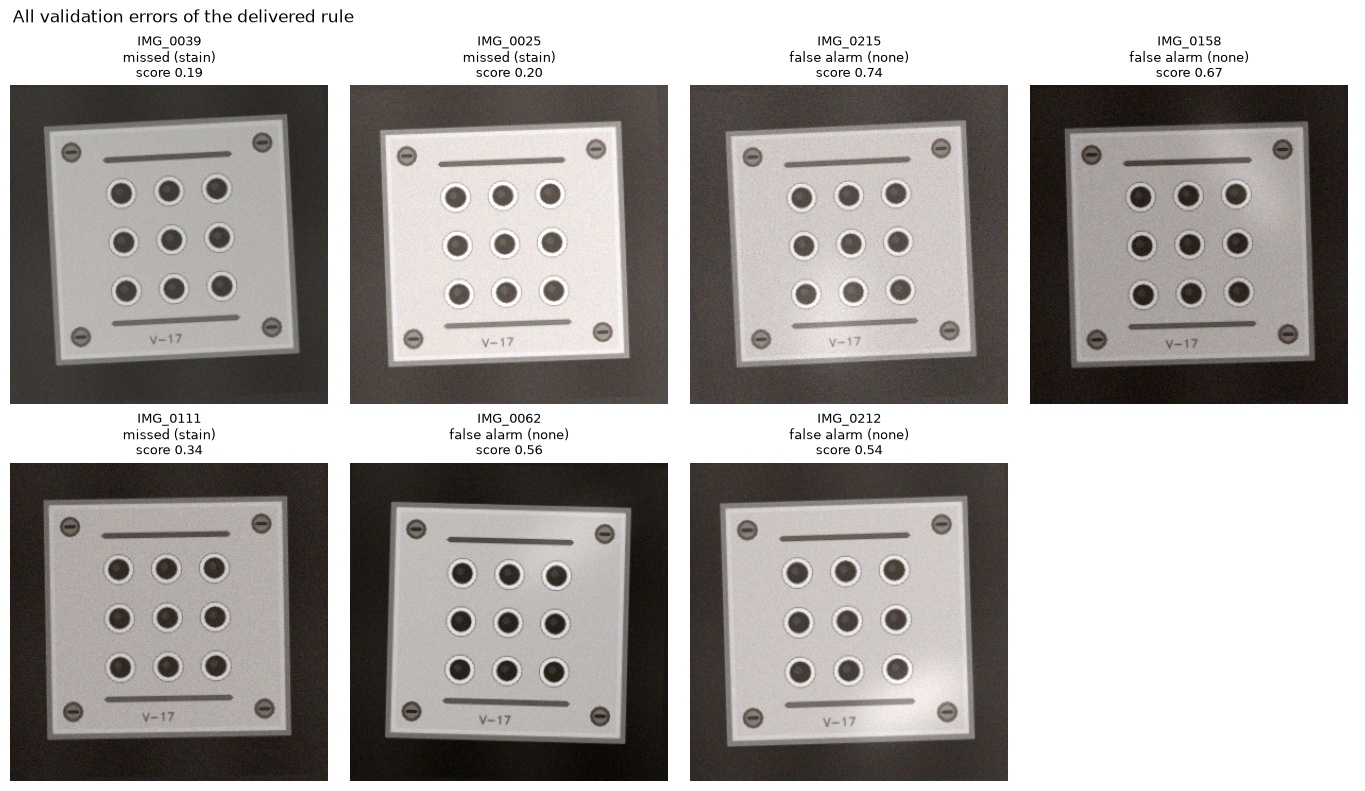

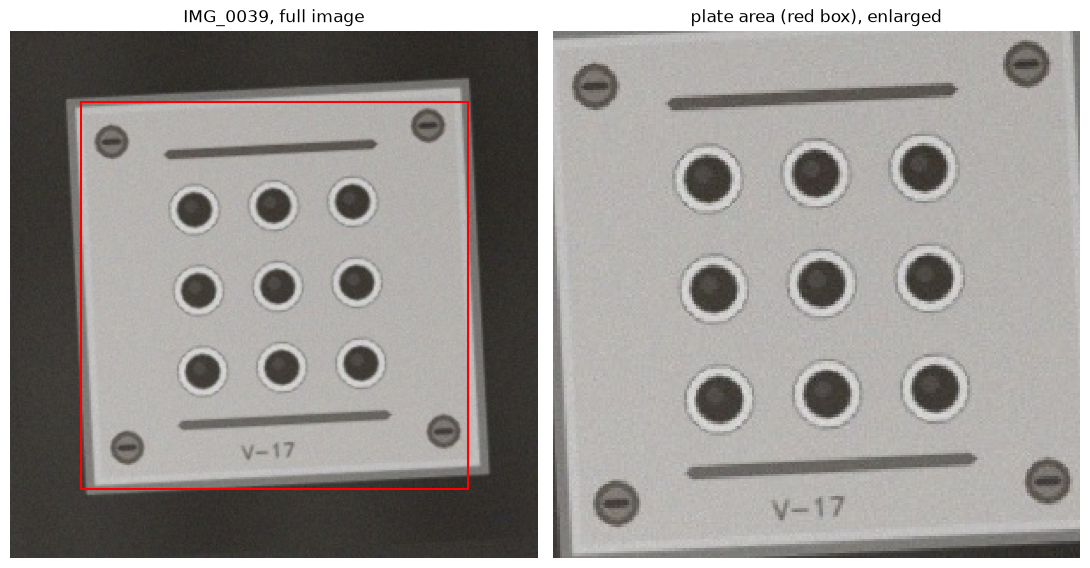

In [16]:
# D.2 — every validation error at a glance, then one image chosen by a rule fixed before looking:
# the wrong prediction with the score farthest from 0.5 (the most confident mistake); ties -> lowest image_id.
errors = errors.assign(distance=(errors["score"] - 0.5).abs()).sort_values(["distance", "image_id"],
                                                                          ascending=[False, True])
chosen = errors.iloc[0]
print(f"chosen: {chosen['image_id']} ({chosen['error']}, marked {chosen['inspector_type']}, {chosen['camera']}, "
      f"score {chosen['score']:.3f}); images tied at that distance: "
      f"{(errors['distance'] == chosen['distance']).sum()}")
print("its measurements vs the normal plate:")
display(pd.DataFrame({"value": add_dark_dev(errors.loc[[chosen.name]], RULE_REF)[RULE_COLS].iloc[0],
                      "typical normal": RULE_TYPICAL, "cut-off (95th)": RULE_CUTS}).round(4))

n_cols = 4
n_rows = int(np.ceil(len(errors) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.4 * n_cols, 3.9 * n_rows), squeeze=False, layout="constrained")
for ax in axes.flat[len(errors):]:
    ax.axis("off")                       # empty panels in the last row
for ax, row in zip(axes.flat, errors.itertuples()):
    img = cv2.imread(str(DATA_DIR / row.file))
    ax.axis("off")
    if img is None:
        ax.set_title(f"{row.image_id}: unreadable", fontsize=9)
        continue
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{row.image_id}\n{row.error} ({row.inspector_type})\nscore {row.score:.2f}", fontsize=9)
fig.suptitle("All validation errors of the delivered rule", x=0.01, ha="left")
fig.savefig(FIG_DIR / "d2_validation_errors.png", dpi=110)

img = cv2.imread(str(DATA_DIR / chosen["file"]))
assert img is not None, f"cannot read {chosen['file']}"
rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
fig, axes = plt.subplots(1, 2, figsize=(11, 5.6))
axes[0].imshow(rgb); axes[0].set_title(f"{chosen['image_id']}, full image")
axes[0].add_patch(plt.Rectangle((40, 40), 220, 220, fill=False, edgecolor="red", linewidth=1.5))
axes[1].imshow(rgb[40:260, 40:260], interpolation="nearest"); axes[1].set_title("plate area (red box), enlarged")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIG_DIR / "d2_chosen_image.png", dpi=110)
print("saved:", FIG_DIR / "d2_validation_errors.png", "and", FIG_DIR / "d2_chosen_image.png")

<div dir="rtl">

**תוצאות ד.2:** כלל הבחירה בחר את **IMG_0039** ‏(CAM-A, מסומנת כ-stain), שהכלל החטיא עם ציון 0.19. לא היה שוויון.

- **המדידות שלה זהות ללוח תקין טיפוסי:** ‏`dark_dev` = 0.0003 (טיפוסי 0.0005, סף 0.0039), ‏`bright_line_len` = 38.2 (בדיוק הערך הטיפוסי, שפת חור), ‏`dent_depth` = 1.10 (טיפוסי 1.05, סף 1.24). כלומר, מבחינת הכלל אין על הלוח שום דבר חריג.
- **גם בהגדלה של אזור הלוח לא רואים כתם** (תצפית חזותית).
- **שתי סיבות אפשריות:**
  1. **התיוג שגוי:** IMG_0039 היא אחת מ-11 תמונות ה-stain שבסעיף ב.1 לא ראינו בהן כתם. אם אין כתם, הכלל צדק והתיוג טעה.
  2. **הכתם חלש מדי לתמונה של 300×300 פיקסלים:** כתם בהיר מדי לא יעבור את סף הכהות של `dark_share` ‏(72% מהדרך בין הרקע ללוח), ולא ייראה גם לעין.
  
  כדי להכריע צריך מידע שאין לנו: את הרכיב עצמו או צילום ברזולוציה גבוהה יותר.
- **המשמעות:** ‏Recall שנמדד מול התיוגים לא יכול להיות טוב יותר מהתיוגים עצמם. שלוש ההחטאות באימות הן בדיוק המקרים האלה.

</div>

<div dir="rtl">

## חלק ה — מסקנות ושימוש ב-AI
התא הבא רק מחשב את המספרים שהסיכום מצטט (לפי אצווה ולפי מצלמה); הוא לא לומד ולא משנה דבר.

</div>

In [17]:
# E — the numbers the summary cites. Rule flags: out-of-fold for development (C.1), the final rule for validation (D.1)
# and for test (C.3). Nothing is fitted or changed here.
flags_labelled = pd.concat([d["rule_pred"], val_95["predicted_defect"]]).astype(int)
labelled = features_all.loc[flags_labelled.index].assign(rule_flag=flags_labelled)
all_images = pd.concat([
    labelled[["batch", "camera", "rule_flag"]].assign(blurred=labelled["sharpness"] < BLUR_SHARPNESS),
    detail[["batch", "camera", "predicted_defect", "blurred"]].rename(columns={"predicted_defect": "rule_flag"}),
])
by_batch = pd.DataFrame({
    "images (train + test)": all_images.groupby("batch").size(),
    "marked defective (train, 42 per batch)": labelled.groupby("batch")["inspector_label"].mean(),
    "flagged by the rule (train + test)": all_images.groupby("batch")["rule_flag"].mean(),
    "CAM-B share (train + test)": all_images.groupby("batch")["camera"].apply(lambda c: (c == "CAM-B").mean()),
    "heavily blurred images": all_images.groupby("batch")["blurred"].sum(),
}).round(2)
print("per batch: the inspector's marks beside the rule's flags and the photo conditions")
display(by_batch)
print("labelled images (n = 168), by camera: share marked by the inspector vs share flagged by the rule")
display(labelled.groupby("camera").agg(n=("image_id", "size"), marked_defective=("inspector_label", "mean"),
                                        flagged_by_rule=("rule_flag", "mean")).round(2))
LOOK_DEFECTIVE = ["IMG_0092", "IMG_0112", "IMG_0133", "IMG_0167"]   # normal-labelled, visible defect (C.1)
normal_dev = add_dark_dev(d[d["inspector_label"] == 0], RULE_REF)
print(f"dark_dev cut-off (95th pct of normal-labelled development images): {normal_dev['dark_dev'].quantile(0.95):.4f}; "
      f"without the {len(LOOK_DEFECTIVE)} with a visible defect: "
      f"{normal_dev.loc[~normal_dev['image_id'].isin(LOOK_DEFECTIVE), 'dark_dev'].quantile(0.95):.4f}")
NO_MARK_STAINS = ["IMG_0004", "IMG_0006", "IMG_0007", "IMG_0011", "IMG_0025", "IMG_0034", "IMG_0039", "IMG_0073",
                  "IMG_0100", "IMG_0111", "IMG_0213"]   # stain-labelled, no visible stain (B.1, visual)
print("stain-labelled images with no visible stain (B.1) by batch:",
      train.loc[train["image_id"].isin(NO_MARK_STAINS), "batch"].value_counts().sort_index().to_dict())
typed = features_all.join(train[["inspector_type"]])
small_dent = typed[(typed["dent_depth"] > RULE_CUTS["dent_depth"]) & (typed["dent_depth"] < 10)]
print(f"labelled images with dent_depth between the cut-off ({RULE_CUTS['dent_depth']:.2f} px) and 10 px: {len(small_dent)};",
      "by type:", small_dent["inspector_type"].value_counts().to_dict(), "| by camera:", small_dent["camera"].value_counts().to_dict())
print(f"smallest dent_depth among edge_chip-labelled images: {typed.loc[typed['inspector_type'] == 'edge_chip', 'dent_depth'].min():.1f} px")

per batch: the inspector's marks beside the rule's flags and the photo conditions


,images (train + test),"marked defective (train, 42 per batch)",flagged by the rule (train + test),CAM-B share (train + test),heavily blurred images
batch,,,,,
BATCH-A,60,0.33,0.22,0.32,1
BATCH-B,60,0.26,0.25,0.37,2
BATCH-C,60,0.43,0.53,0.35,0
BATCH-D,60,0.31,0.35,0.63,6


labelled images (n = 168), by camera: share marked by the inspector vs share flagged by the rule


,n,marked_defective,flagged_by_rule
camera,,,
CAM-A,95,0.32,0.27
CAM-B,73,0.36,0.40


dark_dev cut-off (95th pct of normal-labelled development images): 0.0039; without the 4 with a visible defect: 0.0017
stain-labelled images with no visible stain (B.1) by batch: {'BATCH-A': 7, 'BATCH-B': 3, 'BATCH-D': 1}
labelled images with dent_depth between the cut-off (1.24 px) and 10 px: 9; by type: {'none': 8, 'stain': 1} | by camera: {'CAM-B': 8, 'CAM-A': 1}
smallest dent_depth among edge_chip-labelled images: 10.3 px


<div dir="rtl">

### סיכום
**התוצאה העיקרית (קבוצת האימות, 42 תמונות):** הכלל זיהה 11 מתוך 14 התמונות שהבודק סימן כפגומות, ו-11 מתוך 15 התמונות שהכלל סימן אכן מסומנות כפגומות (Precision ‏0.73 לעומת 33% בבחירה אקראית, Recall ‏0.79).

**1. רכיבים, תנאי צילום או הנתונים?** (פרשנות של הנתונים; ההתראות עצמן אינן בהם)
- **תנאי הצילום:** באצווה D ‏CAM-B צילמה 63% מהתמונות (32%–37% קודם), ושם 6 מתוך 9 התמונות המטושטשות מאוד. הכלל גם מסמן יותר את CAM-B ‏(40% לעומת 27%, כשהבודק סימן 36% ו-32%).
- **הרכיבים:** באצווה C הכלל מסמן 53% מהתמונות, אף שחלק CAM-B בה רגיל (35%), וזה תואם את שיעור התיוגים כפגומים הגבוה בה (43%).
- **הנתונים:** ‏15 מתוך 168 תיוגים נראים מפוקפקים בבדיקה חזותית (11 תמונות stain בלי כתם נראה, 7 מהן באצווה A; ו-4 לוחות "תקינים" עם פגם נראה). גם `shift` לא תואם את שעת הצילום.
- **השערה:** לעלייה בהתראות כנראה יותר מסיבה אחת. זה מעדכן את סעיף א.3, שהסתכל רק על התיוגים.

**2. מגבלות**
- קבוצת האימות קטנה (תמונה אחת מזיזה מדד בכ-7%). ההחטאות הן stain בלי כתם נראה, והתראות השווא הן שקע של שבריר פיקסל (סעיף ד.1).
- הסף של `dent_depth` צמוד מדי, והסף של `dark_dev` מורם על ידי לוחות עם פגם שתויגו כתקינים (0.0039, לעומת 0.0017 בלעדיהם).
- טשטוש מעלים שריטות בהירות (7 תמונות מבחן מטושטשות), והמדידות מותאמות לרכיב הזה בלבד.

**3. מה השפיע על הכלל (גילוי נאות):** הרעיון של שלוש המדידות וההגדרות שלהן הגיעו מחקירה מוקדמת שראתה את תיוגי קבוצת האימות ואת תמונות המבחן (בלי תיוגים); בסעיף ב.1 הסתכלנו ב-5 תמונות stain מהאימות; את דחיסת הציונים הבחנו בציוני המבחן (ההחלטה לשנות התבססה על הפיתוח, ואף החלטה 0/1 לא השתנתה); ושלוש השיטות הושוו על אותה cross-validation. לכן תוצאת האימות עשויה להיות מעט אופטימית.

**4. שימוש ב-AI ואיך הוא נבדק**
- ה-AI כתב את הקוד, ניסח את רוב ההסברים והציע כיוונים. לפני כל הרצה נכתב מה צפוי לצאת, וכל טקסט ומספר נבדקו מול פלטי המחברת.
- **הוא טעה, וזה נתפס:** עריכות בבדיקות עם תשובה ידועה הונחו במקום שגוי; הציון הראשון נדחס סביב 0.5; מונה החורים הראשון מצא 0 חורים ב-83 מתוך 84 לוחות תקינים (בבדיקה מחוץ למחברת) ונזנח; והחקירה המוקדמת הסתכלה בקבוצת האימות (וזה גולה).
- הערות של סוקרים (גם הם AI) נבדקו מול הנתונים לפני שיושמו, וחלקן נדחו. מספרים שנמדדו מודפסים בתאים; ספירות מהסתכלות בתמונות הן תצפיות חזותיות.

**5. הצעדים הבאים:** בדיקה חוזרת של 15 התיוגים החשודים עם הבודק; בדיקת המיקוד והתאורה של CAM-B; והרחבת הסף של `dent_depth` (אף שקע קטן מ-10 פיקסלים אינו שקע בשפה, והקטן האמיתי הוא 10.3), עם בדיקה על תמונות מתויגות חדשות ולא כוונון על נתונים שכבר ראינו.

</div>